# TEC subsets across age groups - all sorts pooled, significance compared across sorts (self-contained, v3)

TECs = `taa_l1 == 'TEC'` at `taa_l2_v2` / `taa_l3` / **`taa_l4`** (14 subsets, the level of main interest), age
groups **infant / paed / adult**. Inputs are data files only (the v6 atlas object, obs only, and the
`curatedAnno_v12` CSV); **no project scripts are imported**. Built from `11_TEC_freq_stackedbar_v2.ipynb`.

**Sections**: 1 load - 2 per-sample tables (TEC fraction per sample with sort; subset counts / proportions) -
3 sort diagnostics - 4 stacked bars (all sorts) - 5 frequency change with age (all sorts, boxplots) -
6 composition under each sort + within-donor paired sorts - 7 significance across sorts - notes.
Outputs: `TEC_compartment/plots|results/TEC_freq/v3_allSorts/`.

In [1]:
import os, warnings
from datetime import datetime
from itertools import combinations
today = datetime.now().strftime("%Y-%m-%d")

import numpy as np
import pandas as pd
import h5py
import hdf5plugin            # the v6 object is blosc-compressed
import anndata as ad
try:
    from anndata.io import read_elem            # anndata >= 0.11
except ImportError:                              # older anndata
    from anndata.experimental import read_elem

from scipy.stats import kruskal, wilcoxon, rankdata, chi2
import scikit_posthocs as sp
from statannotations.Annotator import Annotator

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rcParams, font_manager
from matplotlib.colors import to_rgb, to_hex
from matplotlib.gridspec import GridSpec
import seaborn as sns

from IPython.display import display
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
pd.set_option('display.max_columns', None)
pd.options.display.max_rows = 300
warnings.filterwarnings('ignore', message='This figure includes Axes that are not compatible with tight_layout')
print('pandas', pd.__version__, '| anndata', ad.__version__, '| seaborn', sns.__version__,
      '| matplotlib', matplotlib.__version__)

pandas 2.2.3 | anndata 0.11.4 | seaborn 0.13.2 | matplotlib 3.10.1


In [2]:
REPO = '/nfs/team205/vk8/projects/thymus_ageing_atlas'

# ---- inputs: data files only ----
OBJECT_PATH = f'{REPO}/General_analysis/data/objects/rna/thyAgeing_all_scvi_v6_2026-05-01.zarr'
ANNO_PATH   = f'{REPO}/General_analysis/data/objects/rna/thyAgeing_all_scvi_v6_2026-09-02_curatedAnno_v12.csv'
LEVELS_XLSX = f'{REPO}/General_analysis/data/curated/thyAgeing_full_curatedAnno_v12_2025-09-02_levels.xlsx'  # optional: verifies TEC_ORDER
ARIAL_TTF   = '/nfs/team205/ny1/ThymusSpatialAtlas/software/Arial.ttf'                                       # optional

# ---- outputs (own subfolder, so the v2 outputs of the same date are not overwritten) ----
plot_path = f'{REPO}/TEC_compartment/plots/TEC_freq/v3_allSorts'
results_path = f'{REPO}/TEC_compartment/results/TEC_freq/v3_allSorts'
os.makedirs(plot_path, exist_ok=True)
os.makedirs(results_path, exist_ok=True)
PREFIX = 'thyAgeing_TEC'

# ---- design ----
age_order = ['infant', 'paed', 'adult']      # 'aged' excluded as in v1/v2 (03 showed it; append 'aged' to include it)
levels = ['taa_l2_v2', 'taa_l3', 'taa_l4']   # 4 lineages -> 7 types -> 14 subsets
COMP_COL, COMP = 'taa_l1', ['TEC']           # a list: a bare 'TEC' string would be read by .isin as T, E, C
MIN_CELLS = 100          # >= 100 TEC cells per sample (03 used > 100 cells of the TEC object; no sample has exactly 100)
MIN_CELLS_PAIRED = 50    # looser threshold for the within-donor paired comparison
MAIN_SORTS = None        # main quantification: ALL sorts pooled (the 03 design)
TOT_SORTS = ('TOT',)     # top panel of the stacked bars: TEC as a fraction of all cells, unsorted samples only

# ---- significance across sorts ----
REF_BRACKET = 'all sorts'   # the pooled result every bracket is compared with
ALPHA = 0.05
MIN_DONORS_GROUP = 2        # an age group enters a bracket's Kruskal-Wallis / Dunn with >= 2 donors
N_SUBSAMPLE = 500           # donor-matched random subsamples of the pooled data per bracket
POWER_LEVEL = 0.8           # expected significance above which a lost result is attributed to the sort

SORT_BRACKETS = {
    'TOT':          ('TOT',),            # unsorted
    'CD45N':        ('CD45N',),          # CD45-depleted: all stroma, no selection within TEC
    'CD45NCD3N':    ('CD45NCD3N',),      # CD45- CD3- (adult donors only)
    'EPCAM':        ('EPCAM',),          # EPCAM+ sorted - selects on EPCAM level
    'EPCAM+CD205+': ('EPCAM+CD205+',),   # EPCAM+ CD205+ (LY75): cTEC-enriched
    'CD205+CD49F+': ('CD205+CD49F+',),   # CD205+ ITGA6+ (one infant donor)
    'DGC':          ('DGC',),
    'CD3N':         ('CD3N',),           # CD3-negative fraction - holds ~no TECs
}
COMPOSITE_BRACKETS = {
    'all sorts':    None,                                   # the main quantification
    'TOT+CD45N':    ('TOT', 'CD45N'),                       # v2's main bracket: no TEC-marker selection
    'TEC-enriched': ('EPCAM', 'EPCAM+CD205+', 'CD205+CD49F+'),
}
LEAVE_ONE_OUT = ['EPCAM', 'CD45N', 'TOT', 'EPCAM+CD205+', 'CD205+CD49F+', 'CD45NCD3N']   # 'all sorts' minus each

# within-donor pairs (sort A vs sort B); CD45N is the reference because it does not select within TEC
PAIRS = [(('EPCAM',), ('CD45N',)),
         (('TOT',), ('CD45N',)),
         (('EPCAM+CD205+',), ('CD45N',)),
         (('CD45NCD3N',), ('CD45N',)),
         (('EPCAM',), ('TOT',))]
pair_tag = lambda a, b: f'{"+".join(a)}_vs_{"+".join(b)}'
print(f'main quantification: {"all sorts" if MAIN_SORTS is None else MAIN_SORTS}; MIN_CELLS={MIN_CELLS}; '
      f'reference for significance: {REF_BRACKET}; {N_SUBSAMPLE} subsamples per bracket')

main quantification: all sorts; MIN_CELLS=100; reference for significance: all sorts; 500 subsamples per bracket


In [3]:
# Plot style: the non-default part of General_analysis/scripts/plotting/thyAgeing.mplstyle (Nature sizes:
# 7 pt base, 5 pt tick/axis labels, 6 pt titles/legend titles, 0.5 pt lines, PDF with editable text)
STYLE = {
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'DejaVu Sans'], 'font.size': 7.0,
    'axes.titlesize': 6.0, 'axes.titlepad': 2.0, 'axes.labelsize': 5.0, 'axes.labelpad': 2.0,
    'axes.linewidth': 0.5, 'axes.xmargin': 0, 'axes.ymargin': 0, 'axes.autolimit_mode': 'round_numbers',
    'axes.axisbelow': False,
    'axes.prop_cycle': matplotlib.cycler('color', ['#0173B2', '#DE8F05', '#029E73', '#D55E00', '#CC78BC',
                                                   '#CA9161', '#FBAFE4', '#949494', '#ECE133', '#56B4E9']),
    'xtick.labelsize': 5.0, 'ytick.labelsize': 5.0, 'xtick.major.size': 2, 'ytick.major.size': 2,
    'xtick.minor.size': 1.5, 'ytick.minor.size': 1.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'xtick.major.pad': 1, 'ytick.major.pad': 1, 'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.top': False, 'ytick.right': False,
    'lines.linewidth': 0.5, 'lines.markersize': 4, 'lines.markeredgewidth': 0.5,
    'patch.linewidth': 0.5, 'patch.force_edgecolor': True, 'patch.edgecolor': 'k',
    'legend.fontsize': 5.0, 'legend.title_fontsize': 6.0, 'legend.fancybox': False, 'legend.frameon': True,
    'figure.titlesize': 7.0, 'figure.dpi': 80, 'figure.facecolor': 'w', 'figure.edgecolor': 'w',
    'savefig.dpi': 300, 'savefig.format': 'pdf', 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.1,
    'savefig.transparent': True, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'errorbar.capsize': 3,
}
plt.rcdefaults()
rcParams.update(STYLE)
try:
    font_manager.fontManager.addfont(ARIAL_TTF)
except Exception as e:
    print('Arial font not added (DejaVu Sans is used):', e)

# thyAgeing colour tables (plotting/thyAgeing_colors.csv, in file order, and thyAgeing_greys.csv)
THY_COLORS = {'blue': '#648FFF', 'purple': '#785EF0', 'magenta': '#DC267F', 'orange': '#FE6100',
              'yellow': '#FFB000', 'teal': '#18868F', 'mint': '#738B79', 'pink': '#C169E8',
              'grass': '#82CD29', 'forest': '#124420'}
THY_GREYS = {'grey1': '#f7f7f7', 'grey2': '#cccccc', 'grey3': '#969696', 'grey4': '#636363', 'grey5': '#252525'}

# Cell-type order per level = the TEC rows of the curated annotation table (v12, 2025-09-02)
TEC_ORDER = {
    'taa_l2_v2': ['cTEC', 'mcTEC', 'mTEC', 'TEC-EMT'],
    'taa_l3':    ['cTEC', 'mcTEC', 'mTECI', 'mTECII', 'mTECIII', 'TEC-mim', 'TEC-EMT'],
    'taa_l4':    ['cTECIII', 'cTECII', 'cTECI', 'mcTEC', 'mTECI', 'mTECII', 'mTECIII', 'mTECI-trans',
                  'TEC-myo', 'TEC-neuro', 'TEC-cilliated', 'TEC-iono', 'TEC-tuft', 'TEC-EMT'],
}

# TEC-subset colours of the stacked bar in notebooks_github/03_Frequency_analysis_TEC_v3.ipynb (cell 59c06edb):
# color_dict = {k: v for k, v in zip(tec_broad_ctypes, thyAgeing_colors.values())}, tec_broad_ctypes = taa_l3 order
TEC_L3_COLORS_03 = dict(zip(TEC_ORDER['taa_l3'], THY_COLORS.values()))
TEC_L3_COLORS_03

# Verify TEC_ORDER against the curated table when it is available (the notebook does not depend on it)
if os.path.exists(LEVELS_XLSX):
    try:
        cur = pd.read_excel(LEVELS_XLSX)
        cur = cur.loc[cur['taa_l1'].astype(str) == 'TEC']
        for lvl in levels:
            from_table = [c for c in cur[lvl].astype(str).unique() if c != 'nan'] if lvl in cur.columns else None
            print(f'{lvl}: TEC_ORDER', 'matches' if from_table == TEC_ORDER[lvl] else f'DIFFERS: table gives {from_table}')
    except Exception as e:
        print('could not read the curated table:', e)
else:
    print('curated table not found - TEC_ORDER used as hard-coded')

{'cTEC': '#648FFF',
 'mcTEC': '#785EF0',
 'mTECI': '#DC267F',
 'mTECII': '#FE6100',
 'mTECIII': '#FFB000',
 'TEC-mim': '#18868F',
 'TEC-EMT': '#738B79'}

taa_l2_v2: TEC_ORDER matches
taa_l3: TEC_ORDER matches
taa_l4: TEC_ORDER matches


## Helpers (inlined - no project modules)

Four cells: (1) I/O, figure size, tints, level maps; (2) frequency tables - per-sample counts /
proportions and per-donor compositions with the two donor weightings; (3) Kruskal-Wallis + Dunn and the
grouped boxplot; (4) stacked bars and the sort-comparison plots / tables.

In [4]:
def read_obs(path):
    """obs of an h5ad/'zarr'-named HDF5 file without touching X, layers or embeddings."""
    with h5py.File(path, 'r') as f:
        return read_elem(f['obs'])


def calc_figsize(width='double', width_ratio=1.0, height='half', height_ratio=1.0, margin=0.5):
    """Figure size in inches from mm (Nature: single 89 mm, double 183 mm, half-page height 117 mm)."""
    width = {'double': 183, 'single': 89, 'one-half': 130}.get(width, width) * width_ratio - margin
    height = {'full': 247, 'half': 117}.get(height, height) * height_ratio
    return (width / 25.4, height / 25.4)


def get_tint_palette(base_color, n=4, min_tint=0.2, max_tint=1.0):
    """n tints of base_color from pale (min_tint) to full (max_tint), as hex."""
    r, g, b = to_rgb(base_color)
    return [to_hex((1 - l + l * r, 1 - l + l * g, 1 - l + l * b)) for l in np.linspace(min_tint, max_tint, n)]


def level_map(obs, mask, from_level, to_level):
    """Cell type at `from_level` -> cell type at `to_level` among `mask` cells. NB obs[[a, a]] gives
    duplicate columns and silently breaks set_index/zip, hence the identity case."""
    if from_level == to_level:
        return {ct: ct for ct in obs.loc[mask, from_level].astype(str).unique()}
    sub = obs.loc[mask, [from_level, to_level]].astype(str).drop_duplicates()
    if sub[from_level].duplicated().any():
        print(f'WARNING: {from_level} is not nested in {to_level}:',
              sub.loc[sub[from_level].duplicated(keep=False)].values.tolist())
    return dict(zip(sub[from_level], sub[to_level]))


def ordered_types(present, level):
    """Cell types at `level` in curated order, then anything present that the table misses."""
    present = set(present)
    ordered = [c for c in TEC_ORDER[level] if c in present]
    missed = sorted(present - set(ordered))
    if missed:
        print(f'{level}: not in TEC_ORDER, appended: {missed}')
    return ordered + missed

In [5]:
def per_sample_table(obs, comp_col=COMP_COL, comp_values=COMP, extra_meta=()):
    """One row per sample: donor / age group / sort (+ extra metadata), annotated cells, TEC cells, TEC
    fraction. This is the base table of the notebook."""
    meta_cols = ['donor', 'age_group', 'sort'] + [c for c in extra_meta if c in obs.columns]
    g = obs.groupby('sample', observed=True)
    for c in meta_cols:   # every sample must map to one donor / age group / sort
        bad = g[c].nunique(dropna=False)
        bad = bad[bad > 1]
        if len(bad):
            print(f'WARNING: {c} is not unique within sample for {bad.index.tolist()}')
    t = g[meta_cols].first()
    t['n_cells_total'] = g.size()
    is_comp = obs[comp_col].astype(str).isin(list(comp_values))
    t['n_TEC'] = obs.loc[is_comp].groupby('sample', observed=True).size().reindex(t.index).fillna(0).astype(int)
    t['frac_TEC'] = t['n_TEC'] / t['n_cells_total']
    for c in meta_cols:
        t[c] = t[c].astype(str) if c != 'age_group' else pd.Categorical(t[c].astype(str), categories=age_order, ordered=True)
    t.index = t.index.astype(str)
    t.index.name = 'sample'
    return t


def per_sample_counts(obs, mask, level, sample_index):
    """sample x cell-type counts (wide) among `mask` cells, one row for every sample in `sample_index`."""
    ct = pd.crosstab(obs.loc[mask, 'sample'].astype(str), obs.loc[mask, level].astype(str))
    ct = ct.reindex(sample_index).fillna(0).astype(int)
    ct.index.name, ct.columns.name = 'sample', 'cell_type'
    return ct


def samples_passing(meta, sorts=None, min_cells=MIN_CELLS):
    """Samples of `sorts` (None = all) with >= min_cells TEC cells."""
    sel = meta['n_TEC'] >= min_cells
    if sorts is not None:
        sel &= meta['sort'].isin(list(sorts))
    return meta.index[sel]


def donor_composition(counts, meta, sorts=None, min_cells=MIN_CELLS, denominator='TEC'):
    """Per-donor composition from the samples of `sorts` with >= min_cells TEC cells.

    denominator='TEC' : proportion within TEC per sample -> every donor's composition sums to 1 and donors
                        weigh equally downstream (used for the sort comparison and the boxplots).
    denominator='all' : proportion of all annotated cells per sample -> the original population_stacked_plot
                        weighting, where a donor weighs in proportion to its TEC yield once renormalised.
    Returns a long DataFrame: donor, age_group, cell_type, prop, n_samples, n_cells (TEC cells of the donor
    in the passing samples). The proportion per sample is averaged over a donor's samples (donor = replicate).
    """
    keep = samples_passing(meta, sorts, min_cells)
    cols = ['donor', 'age_group', 'cell_type', 'prop', 'n_samples', 'n_cells']
    if len(keep) == 0:
        return pd.DataFrame(columns=cols)
    c = counts.loc[keep]
    denom = c.sum(axis=1) if denominator == 'TEC' else meta.loc[keep, 'n_cells_total']
    p = c.div(denom.replace(0, np.nan), axis=0).fillna(0)
    p = p.join(meta.loc[keep, ['donor', 'age_group']])
    wide = p.groupby(['donor', 'age_group'], observed=True)[list(counts.columns)].mean()
    long = wide.reset_index().melt(id_vars=['donor', 'age_group'], var_name='cell_type', value_name='prop')
    info = meta.loc[keep].groupby('donor', observed=True).agg(n_samples=('n_TEC', 'size'), n_cells=('n_TEC', 'sum'))
    long = long.merge(info, left_on='donor', right_index=True, how='left')
    long['donor'] = long['donor'].astype(str)
    long['age_group'] = long['age_group'].astype(str)
    return long[cols].sort_values(['age_group', 'donor', 'cell_type']).reset_index(drop=True)


def composition_by_age(per_donor, ctypes, age_order=age_order):
    """Mean over donors per age group, renormalised over `ctypes` -> (cell type x age group, n donors per age)."""
    m = (per_donor.loc[per_donor['cell_type'].isin(ctypes)]
         .groupby(['age_group', 'cell_type'])['prop'].mean().unstack('cell_type')
         .reindex(index=age_order, columns=list(ctypes)).fillna(0))
    rel = m.div(m.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
    n = per_donor.groupby('age_group')['donor'].nunique().reindex(age_order).fillna(0).astype(int)
    return rel.T, n


def compartment_fraction_by_age(meta, sorts=TOT_SORTS, age_order=age_order):
    """TEC as a fraction of all annotated cells: per-sample fraction -> donor mean -> age-group mean +/- sd
    (all samples of `sorts`, no min_cells filter, as in the published figure)."""
    m = meta.loc[meta['sort'].isin(list(sorts))]
    d = m.groupby(['donor', 'age_group'], observed=True)['frac_TEC'].mean().reset_index()
    return (d.groupby('age_group', observed=True)['frac_TEC']
            .agg(mean_prop='mean', sd_prop='std', n_donors='size').reindex(age_order))


def composition_by_bracket(counts, meta, brackets, min_cells=MIN_CELLS):
    """donor_composition for every bracket (name -> sorts tuple, None = all sorts) -> (summary, per_donor)."""
    per_donor = []
    for name, sorts in brackets.items():
        df = donor_composition(counts, meta, sorts=sorts, min_cells=min_cells)
        if not df.empty:
            per_donor.append(df.assign(bracket=name))
    if not per_donor:
        return pd.DataFrame(), pd.DataFrame()
    per_donor = pd.concat(per_donor, ignore_index=True)
    per_donor['bracket'] = pd.Categorical(per_donor['bracket'], categories=list(brackets), ordered=True)
    summary = (per_donor.groupby(['bracket', 'age_group', 'cell_type'], observed=True)
               .agg(mean_prop=('prop', 'mean'), sd_prop=('prop', 'std'), n_donors=('prop', 'size'))
               .reset_index())
    return summary, per_donor

In [6]:
def kruskal_by_group(data, y, x, grouping_var):
    """Kruskal-Wallis of `y` across the levels of `x`, separately for each value of `grouping_var`."""
    def _kw(k):
        groups = [k.loc[k[x] == g, y].dropna() for g in k[x].unique()]
        groups = [g for g in groups if len(g) > 0]
        if len(groups) < 2 or len(pd.concat(groups).unique()) < 2:
            return pd.Series({'statistic': np.nan, 'pvalue': 1.0})
        res = kruskal(*groups, nan_policy='omit')
        return pd.Series({'statistic': res.statistic, 'pvalue': res.pvalue})
    out = data.groupby(grouping_var, observed=True).apply(_kw)
    out = out.apply(pd.Series) if not isinstance(out, pd.DataFrame) else out
    out.columns = ['statistic', 'pvalue']
    out['pvalue_signif'] = pd.cut(out['pvalue'], bins=[0, 1e-4, 1e-3, 1e-2, 5e-2, 1],
                                  labels=['****', '***', '**', '*', ''], include_lowest=True)
    return out


def dunn_by_group(data, y, x, grouping_var):
    """Post-hoc Dunn test (FDR-BH within each `grouping_var`) between the levels of `x`, long format."""
    data = data.dropna(subset=[y])
    res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
    res = (res.reset_index(names=[grouping_var, 'group1'])
           .melt(id_vars=[grouping_var, 'group1'], var_name='group2', value_name='pvalue'))
    res = res.loc[res['group1'] != res['group2']].copy()
    res['handle'] = res.apply(lambda k: '_'.join([str(k[grouping_var])] + sorted([str(k['group1']), str(k['group2'])])), axis=1)
    res = res.drop_duplicates(subset=['handle']).drop(columns='handle')
    res['pvalue_signif'] = pd.cut(res['pvalue'], bins=[0, 1e-4, 1e-3, 1e-2, 5e-2, 1],
                                  labels=['****', '***', '**', '*', ''], include_lowest=True)
    return res


def plot_grouped_boxplot(data, x, y, hue, order, hue_order, x_label, y_label, legend_title,
                         pval_format='{:.2e}', alpha=0.05, add_stats=True, save_stats=None,
                         format_percent=False, palette='colorblind', figsize=(4, 3), ylim=None,
                         legend_kwargs=None, remove_legend=False, add_jitter=True, annotator_args=None):
    """Grouped boxplot (x = cell type, hue = age group) with per-cell-type Kruskal-Wallis and, where
    p < alpha, post-hoc Dunn pairs annotated (statannotations). `save_stats` writes _summaryStats.csv,
    _kruskal.csv and _dunn.csv. Same drawing as plotting.utils.plot_grouped_boxplot."""
    if save_stats:
        (data.groupby([x, hue], observed=True)
         .agg(n_obs=(y, 'count'), mean=(y, lambda v: round(v.mean(), 4)), sd=(y, lambda v: round(v.std(), 4)),
              median=(y, lambda v: round(v.median(), 4)))
         .to_csv(f'{save_stats}_summaryStats.csv', float_format='%.4f'))
    pairs, pvals = [], []
    if add_stats:
        print('Performing Kruskal-Wallis and Dunn tests')
        n_groups = data[[hue, x]].drop_duplicates().groupby([x], observed=True).size()
        kw = kruskal_by_group(data.loc[data[x].isin(n_groups[n_groups > 1].index)], y=y, x=hue, grouping_var=x)
        signif = kw.loc[kw['pvalue'] < alpha].index
        if save_stats:
            kw.to_csv(f'{save_stats}_kruskal.csv')
        if len(signif) == 0:
            print('No significant results found')
        else:
            dunn = dunn_by_group(data[data[x].isin(signif)], y=y, x=hue, grouping_var=x)
            dunn[x] = pd.Categorical(dunn[x], categories=order, ordered=True)
            dunn = dunn.sort_values(x)
            if save_stats:
                dunn.to_csv(f'{save_stats}_dunn.csv')
            for row in dunn.loc[dunn['pvalue'] < alpha].itertuples():
                pairs.append(((getattr(row, x), row.group1), (getattr(row, x), row.group2)))
                pvals.append(row.pvalue)

    plt.figure(figsize=figsize)
    ax = plt.axes()
    g = sns.boxplot(data=data, x=x, y=y, hue=hue, palette=palette, hue_order=hue_order, order=order,
                    fill=True, gap=0.1, showfliers=False, showcaps=False, medianprops={'color': 'white'},
                    whiskerprops={'color': 'black', 'linestyle': 'solid'}, boxprops={'linewidth': 0})
    for i in range(len(g.patches)):   # whiskers in the box colour
        patch_color = g.patches[i].get_facecolor()
        if 3 * i < len(g.lines):
            g.lines[3 * i].set_color(patch_color)
        if 3 * i + 1 < len(g.lines):
            g.lines[3 * i + 1].set_color(patch_color)
    handles, labels = g.get_legend_handles_labels()
    if add_jitter:
        g = sns.stripplot(data=data, x=x, y=y, order=order, dodge=True, jitter=True, hue=hue,
                          hue_order=hue_order, size=1.5, color='black', ax=ax, legend=False)
    if g.get_legend() is not None:
        g.get_legend().remove()
    if not remove_legend:
        g.legend(handles, labels, title=legend_title, **(legend_kwargs or {}))
    if add_stats and len(pairs) > 0:
        anno = dict(line_offset=0.05, text_offset=0.05, line_offset_to_group=None)
        anno.update(annotator_args or {})
        ann = Annotator(ax, pairs, data=data, x=x, y=y, hue=hue, hue_order=hue_order, order=order, verbose=False)
        ann.configure(test=None, pvalue_format_string=pval_format, line_height=0, **anno,
                      line_width=plt.rcParams['lines.linewidth'])
        ann.set_pvalues(pvals)
        ann.annotate(line_offset=anno['line_offset'], line_offset_to_group=anno['line_offset_to_group'])
    g.set_xlabel(x_label)
    g.set_ylabel(y_label)
    g.tick_params(axis='x', rotation=90)
    if ylim:
        plt.ylim(ylim)
    if format_percent:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    sns.despine(offset=2, trim=True)
    plt.tight_layout()
    return g

In [7]:
def stacked_bar_plot(rel, top=None, palette=None, n_donors=None, figsize=calc_figsize(width=40, height=45),
                     legend_kwargs=None, plt_path=None, title=None):
    """Top: compartment as a proportion of all cells (mean +/- sd over donors); bottom: stacked relative
    frequency within the compartment. `rel` = cell type x age group (columns sum to 1), `top` = output of
    compartment_fraction_by_age (None drops the panel). Same layout as plotting.utils.population_stacked_plot."""
    ages = list(rel.columns)
    fig = plt.figure(figsize=figsize)
    if top is None:
        ax0, ax1 = None, fig.add_subplot(GridSpec(1, 1)[0])
    else:
        gs = GridSpec(2, 1, height_ratios=[1, 3], hspace=0.1)
        ax0, ax1 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
        top = top.reindex(ages)
        ymax = (top['mean_prop'].fillna(0) + top['sd_prop'].fillna(0)).max()
        ax0.bar(ages, top['mean_prop'].fillna(0), yerr=top['sd_prop'].fillna(0),
                color=THY_GREYS['grey3'], capsize=1, linewidth=0.25)
        ax0.set_ylabel('Proportion\n(of total)')
        ax0.set_xticks([])
        ax0.set_xlabel('')
        ax0.set_ylim(0, round(ymax, 2) if ymax > 0.1 else 0.11)
        ax0.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
        sns.despine(ax=ax0, offset=2, trim=True)
    bottom = np.zeros(len(ages))
    for ct in rel.index:
        vals = rel.loc[ct].values
        ax1.bar(ages, vals, bottom=bottom, label=ct, color=(palette or {}).get(ct, '#cccccc'), linewidth=0.25)
        bottom += vals
    ax1.set_xlabel('Age group')
    ax1.set_ylabel('Relative frequency\n(within compartment)')
    ax1.set_xticks(range(len(ages)))
    ax1.set_xticklabels(ages if n_donors is None else [f'{a}\n(n={int(n_donors.get(a, 0))})' for a in ages], rotation=0)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax1.legend(**{'title': 'Cell type', 'bbox_to_anchor': (1.05, 1), 'loc': 'upper left', 'frameon': False,
                  **(legend_kwargs or {})})
    sns.despine(ax=ax1, offset=2, trim=True)
    if title:
        fig.suptitle(title, fontsize=6)
    plt.tight_layout()
    if plt_path is not None:
        plt.savefig(plt_path, bbox_inches='tight')
    return fig


def composition_grid_plot(summary, ctypes, palette, brackets=None, age_order=age_order, ncols=None,
                          panel_size=(1.0, 1.5), legend_kwargs=None, plt_path=None, title=None):
    """One stacked-bar panel per sort bracket (age groups on x) from composition_by_bracket's summary.
    Bars are renormalised over `ctypes`; an age group without donors stays empty; n donors above each bar."""
    brackets = list(brackets) if brackets is not None else list(pd.unique(summary['bracket'].astype(str)))
    n = len(brackets)
    ncols = ncols or n
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_size[0] * ncols + 1.0, panel_size[1] * nrows),
                             sharey=True, squeeze=False)
    for ax, name in zip(axes.flat, brackets):
        sub = summary.loc[summary['bracket'].astype(str) == name]
        mat = (sub.pivot_table(index='cell_type', columns='age_group', values='mean_prop', observed=False)
               .reindex(index=list(ctypes), columns=list(age_order)).fillna(0))
        mat = (mat / mat.sum(axis=0).replace(0, np.nan)).fillna(0)
        n_donors = sub.groupby('age_group')['n_donors'].max().reindex(age_order).fillna(0).astype(int)
        bottom = np.zeros(len(age_order))
        for ct in ctypes:
            vals = mat.loc[ct].values
            ax.bar(range(len(age_order)), vals, bottom=bottom, label=ct, color=palette.get(ct, '#cccccc'),
                   linewidth=0.25, width=0.8)
            bottom += vals
        for i, a in enumerate(age_order):
            ax.text(i, 1.02, f'n={int(n_donors[a])}', ha='center', va='bottom', fontsize=4.5)
        ax.set_title(name, fontsize=6, pad=9)
        ax.set_xticks(range(len(age_order)))
        ax.set_xticklabels(age_order, rotation=90)
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
        sns.despine(ax=ax, offset=2, trim=True)
        ax.tick_params(axis='x', labelrotation=90)   # after despine: trim=True resets the rotation
    for ax in list(axes.flat)[n:]:
        ax.axis('off')
    for r in range(nrows):
        axes[r, 0].set_ylabel('Relative frequency\n(within compartment)')
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, **{'title': 'Cell type', 'bbox_to_anchor': (1.0, 0.95), 'loc': 'upper left',
                                   'frameon': False, **(legend_kwargs or {})})
    if title:
        fig.suptitle(title, fontsize=6, y=1.02)
    plt.tight_layout()
    if plt_path is not None:
        plt.savefig(plt_path, bbox_inches='tight')
    return fig


def paired_sort_table(counts, meta, sort_a, sort_b, min_cells=MIN_CELLS_PAIRED, label_a=None, label_b=None):
    """Within-donor comparison of two sort brackets: donors with a passing sample in both. Per cell type
    log2_ratio = log2((prop_a + h) / (prop_b + h)) with a half-cell pseudo-count h = 0.5 / min(n_cells_a,
    n_cells_b) per donor, so an absent cell type gives a finite ratio bounded by the sampling depth."""
    a = donor_composition(counts, meta, sorts=sort_a, min_cells=min_cells)
    b = donor_composition(counts, meta, sorts=sort_b, min_cells=min_cells)
    label_a = label_a or '+'.join(sort_a)
    label_b = label_b or '+'.join(sort_b)
    cols = ['donor', 'age_group', 'cell_type', 'prop_a', 'prop_b', 'n_cells_a', 'n_cells_b', 'n_samples_a',
            'n_samples_b', 'pseudo', 'log2_ratio', 'sort_a', 'sort_b']
    common = sorted(set(a['donor']) & set(b['donor'])) if not (a.empty or b.empty) else []
    if not common:
        return pd.DataFrame(columns=cols)
    a = a.loc[a['donor'].isin(common)].rename(columns={'prop': 'prop_a', 'n_cells': 'n_cells_a', 'n_samples': 'n_samples_a'})
    b = b.loc[b['donor'].isin(common)].rename(columns={'prop': 'prop_b', 'n_cells': 'n_cells_b', 'n_samples': 'n_samples_b'})
    m = a.merge(b, on=['donor', 'age_group', 'cell_type'], how='outer')
    m[['prop_a', 'prop_b']] = m[['prop_a', 'prop_b']].fillna(0.0)
    for c in ['n_cells_a', 'n_samples_a', 'n_cells_b', 'n_samples_b']:
        m[c] = m.groupby('donor')[c].transform('max').astype(int)
    m['pseudo'] = 0.5 / np.minimum(m['n_cells_a'], m['n_cells_b'])
    m['log2_ratio'] = np.log2((m['prop_a'] + m['pseudo']) / (m['prop_b'] + m['pseudo']))
    m['sort_a'] = label_a
    m['sort_b'] = label_b
    return m[cols].sort_values(['cell_type', 'donor']).reset_index(drop=True)


def paired_sort_summary(paired, ctypes=None, min_donors_test=5):
    """Median log2 ratio per cell type over donors, direction counts, two-sided Wilcoxon signed-rank p from
    min_donors_test donors (the exact test floors at 2 / 2**n: 0.0625 at n = 5, 0.031 at n = 6)."""
    rows = []
    for ct, sub in paired.groupby('cell_type'):
        x = sub['log2_ratio'].values.astype(float)
        p = np.nan
        if len(x) >= min_donors_test and np.any(x != 0):
            try:
                p = float(wilcoxon(x, alternative='two-sided').pvalue)
            except ValueError:
                p = np.nan
        rows.append({'cell_type': ct, 'n_donors': len(x), 'mean_prop_a': sub['prop_a'].mean(),
                     'mean_prop_b': sub['prop_b'].mean(), 'median_log2_ratio': float(np.median(x)),
                     'n_up': int((x > 0).sum()), 'n_down': int((x < 0).sum()), 'wilcoxon_p': p})
    out = pd.DataFrame(rows).set_index('cell_type')
    if ctypes is not None:
        out = out.reindex([c for c in ctypes if c in out.index])
    return out


def paired_sort_plot(paired, ctypes, palette=None, age_order=age_order, floor=1e-3, figsize=None,
                     plt_path=None, title=None):
    """Left: per-donor log2 ratio per cell type (points by age group, black tick = median, dashed = no
    effect). Right: prop_b (x) vs prop_a (y) per donor and cell type, log axes, identity line; values below
    `floor` are drawn at it."""
    ctypes = [c for c in ctypes if c in set(paired['cell_type'])]
    palette = palette or {}
    ages = [a for a in age_order if a in set(paired['age_group'])]
    age_pal = dict(zip(ages, get_tint_palette(THY_COLORS['magenta'], n=max(len(ages), 2), min_tint=0.3)))
    label_a, label_b = str(paired['sort_a'].iloc[0]), str(paired['sort_b'].iloc[0])
    figsize = figsize or (0.3 * len(ctypes) + 3.6, 2.0)
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=figsize,
                                   gridspec_kw={'width_ratios': [max(len(ctypes) * 0.3, 1.2), 1.6], 'wspace': 0.45})
    rng = np.random.default_rng(0)
    for i, ct in enumerate(ctypes):
        sub = paired.loc[paired['cell_type'] == ct]
        ax0.scatter(i + rng.uniform(-0.2, 0.2, len(sub)), sub['log2_ratio'], s=7, zorder=3, linewidths=0,
                    c=[age_pal.get(str(a), '#999999') for a in sub['age_group']])
        ax0.hlines(sub['log2_ratio'].median(), i - 0.32, i + 0.32, color='k', linewidth=0.8, zorder=4)
    ax0.axhline(0, color='grey', linewidth=0.5, linestyle='--', zorder=1)
    ax0.set_xticks(range(len(ctypes)))
    ax0.set_xticklabels(ctypes, rotation=90)
    ax0.set_ylabel(f'log2 [{label_a} / {label_b}]\n(within donor)')
    for a in ages:
        ax0.scatter([], [], s=7, c=age_pal[a], label=a)
    ax0.legend(title='Age group', frameon=False, fontsize=4.5, title_fontsize=5, loc='best',
               handletextpad=0.2, borderaxespad=0.2)
    sns.despine(ax=ax0, offset=2, trim=True)
    ax0.tick_params(axis='x', labelrotation=90)   # after despine: trim=True resets the rotation
    for ct in ctypes:
        sub = paired.loc[paired['cell_type'] == ct]
        ax1.scatter(sub['prop_b'].clip(lower=floor), sub['prop_a'].clip(lower=floor), s=7, linewidths=0,
                    color=palette.get(ct, '#999999'), label=ct, zorder=3)
    ax1.plot([floor, 1], [floor, 1], color='grey', linewidth=0.5, linestyle='--', zorder=1)
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.set_xlim(floor * 0.8, 1.2)
    ax1.set_ylim(floor * 0.8, 1.2)
    ax1.set_xlabel(f'{label_b}\n(fraction of compartment)')
    ax1.set_ylabel(f'{label_a}\n(fraction of compartment)')
    ax1.legend(title='Cell type', frameon=False, fontsize=4.5, title_fontsize=5, bbox_to_anchor=(1.02, 1),
               loc='upper left', handletextpad=0.2, borderaxespad=0.0, ncol=2 if len(ctypes) > 9 else 1)
    sns.despine(ax=ax1, offset=2)
    fig.suptitle(title or f'{label_a} vs {label_b}: {paired["donor"].nunique()} donors with both sorts',
                 fontsize=6, y=1.03)
    if plt_path is not None:
        plt.savefig(plt_path, bbox_inches='tight')
    return fig


def age_trend_by_bracket(per_donor, age_order=age_order, min_donors=3, ref=('infant', 'adult'), eps=1e-3):
    """Per bracket x cell type: donors and median proportion per age group, log2 of median ref[1] over
    median ref[0] (eps added to both) and a Kruskal-Wallis p across the age groups with >= min_donors
    donors (NaN when fewer than two such groups). p-values are raw, as in the boxplots."""
    rows = []
    for (br, ct), sub in per_donor.groupby(['bracket', 'cell_type'], observed=True):
        groups = {a: sub.loc[sub['age_group'] == a, 'prop'].values.astype(float) for a in age_order}
        tested = {a: g for a, g in groups.items() if len(g) >= min_donors}
        p = np.nan
        if len(tested) >= 2 and len(np.unique(np.concatenate(list(tested.values())))) > 1:
            p = float(kruskal(*tested.values()).pvalue)
        row = {'bracket': br, 'cell_type': ct}
        row.update({f'n_{a}': len(g) for a, g in groups.items()})
        row.update({f'median_{a}': (float(np.median(g)) if len(g) else np.nan) for a, g in groups.items()})
        lo, hi = groups[ref[0]], groups[ref[1]]
        row[f'log2_{ref[1]}_vs_{ref[0]}'] = (float(np.log2((np.median(hi) + eps) / (np.median(lo) + eps)))
                                             if len(lo) and len(hi) else np.nan)
        row['kruskal_p'] = p
        row['age_groups_tested'] = ','.join(tested)
        rows.append(row)
    out = pd.DataFrame(rows)
    out['bracket'] = pd.Categorical(out['bracket'], categories=per_donor['bracket'].cat.categories, ordered=True)
    return out

In [8]:
def stars(p, alpha=ALPHA):
    return '' if pd.isna(p) else ('***' if p < 1e-3 else '**' if p < 1e-2 else '*' if p < alpha else 'ns')


def kruskal_columns(samples):
    """Kruskal-Wallis for every column at once. samples: list of (n_group, m) arrays -> m p-values.
    Same statistic as scipy.stats.kruskal (average ranks, tie correction, chi2 with k - 1 df); NaN where all
    values in a column are identical."""
    x = np.vstack(samples)
    N, m = x.shape
    ranks = rankdata(x, axis=0)
    bounds = np.cumsum([0] + [s.shape[0] for s in samples])
    ssbn = sum(ranks[bounds[i]:bounds[i + 1]].sum(axis=0) ** 2 / (bounds[i + 1] - bounds[i])
               for i in range(len(samples)))
    h = 12.0 / (N * (N + 1)) * ssbn - 3 * (N + 1)
    ties = np.array([((c := np.unique(x[:, j], return_counts=True)[1]) ** 3 - c).sum() for j in range(m)], float)
    corr = 1 - ties / (N ** 3 - N)
    with np.errstate(divide='ignore', invalid='ignore'):
        h = np.where(corr > 0, h / corr, np.nan)
    return chi2.sf(h, len(samples) - 1)


def significance_by_bracket(per_donor, age_order=age_order, min_donors=MIN_DONORS_GROUP):
    """Kruskal-Wallis across age groups + Dunn (FDR-BH within a cell type) for every bracket x cell type of a
    composition_by_bracket per-donor table. An age group enters the test with >= min_donors donors; a bracket is
    testable with >= 2 such groups. `direction` = sign of median(last tested group) - median(first tested group)."""
    rows = []
    for (br, ct), sub in per_donor.groupby(['bracket', 'cell_type'], observed=True):
        groups = {a: sub.loc[sub['age_group'] == a, 'prop'].to_numpy(float) for a in age_order}
        tested = [a for a in age_order if len(groups[a]) >= min_donors]
        row = {'bracket': str(br), 'cell_type': ct}
        row.update({f'n_{a}': len(groups[a]) for a in age_order})
        row.update({f'median_{a}': (float(np.median(groups[a])) if len(groups[a]) else np.nan) for a in age_order})
        row.update({'groups_tested': ','.join(tested), 'testable': len(tested) >= 2, 'kw_stat': np.nan,
                    'kw_p': np.nan, 'direction': np.nan, 'log2_last_vs_first': np.nan})
        row.update({f'dunn_p_{a}_vs_{b}': np.nan for a, b in combinations(age_order, 2)})
        if row['testable']:
            vals = np.concatenate([groups[a] for a in tested])
            if np.unique(vals).size > 1:
                res = kruskal(*[groups[a] for a in tested])
                row['kw_stat'], row['kw_p'] = float(res.statistic), float(res.pvalue)
                d = pd.DataFrame({'prop': vals, 'age': np.repeat(tested, [len(groups[a]) for a in tested])})
                dm = sp.posthoc_dunn(d, val_col='prop', group_col='age', p_adjust='fdr_bh')
                for a, b in combinations(tested, 2):
                    row[f'dunn_p_{a}_vs_{b}'] = float(dm.loc[a, b])
            else:
                row['kw_p'] = 1.0            # all donors identical (e.g. all zero), as the boxplot helper does
            m0, m1 = row[f'median_{tested[0]}'], row[f'median_{tested[-1]}']
            row['direction'] = float(np.sign(m1 - m0))
            row['log2_last_vs_first'] = float(np.log2((m1 + 1e-3) / (m0 + 1e-3)))
        rows.append(row)
    out = pd.DataFrame(rows)
    out['kw_signif'] = out['kw_p'].map(stars)
    return out


def expected_significance(ref_per_donor, target_n, ctypes, n_iter=N_SUBSAMPLE, alpha=ALPHA, seed=0):
    """Fraction of n_iter donor-matched random subsamples of the reference bracket (target_n[age] donors drawn
    without replacement per age group) in which Kruskal-Wallis reaches p < alpha, per cell type: the chance of
    calling the pooled effect significant with this many donors, whatever the sort."""
    wide = (ref_per_donor.pivot_table(index=['donor', 'age_group'], columns='cell_type', values='prop')
            .reindex(columns=list(ctypes)).fillna(0))
    ages = np.asarray(wide.index.get_level_values('age_group'))
    pools = {a: wide.to_numpy()[ages == a] for a in target_n}
    n = {a: min(int(k), len(pools[a])) for a, k in target_n.items()}
    if any(n[a] < int(target_n[a]) for a in n):
        print(f'WARNING: reference has fewer donors than requested {target_n} - capped at {n}')
    rng = np.random.default_rng(seed)
    hits = np.zeros(len(ctypes))
    for _ in range(n_iter):
        draw = [pools[a][rng.choice(len(pools[a]), size=n[a], replace=False)] for a in n]
        hits += np.nan_to_num(kruskal_columns(draw), nan=1.0) < alpha
    return pd.Series(hits / n_iter, index=list(ctypes))


VERDICT_CODE = {'reference': '', 'significant in both': '', 'ns in both': '', 'not testable': '',
                'lost, too few donors': 'u', 'lost, despite power': 'L', 'gained': 'G',
                'significant in both, direction differs': 'D'}


def classify_vs_reference(sig, ref_bracket=REF_BRACKET, alpha=ALPHA, power_level=POWER_LEVEL):
    """Compare every bracket's Kruskal-Wallis result with the reference bracket, per cell type."""
    ref = sig.loc[sig['bracket'] == ref_bracket].set_index('cell_type')
    out = sig.copy()
    out['ref_kw_p'] = out['cell_type'].map(ref['kw_p'])
    out['ref_direction'] = out['cell_type'].map(ref['direction'])

    def _verdict(r):
        if r['bracket'] == ref_bracket:
            return 'reference'
        if not r['testable'] or pd.isna(r['kw_p']):
            return 'not testable'
        s, rs = r['kw_p'] < alpha, r['ref_kw_p'] < alpha
        if s and rs:
            return 'significant in both' if r['direction'] == r['ref_direction'] else 'significant in both, direction differs'
        if rs:
            return 'lost, despite power' if r['expected_signif'] >= power_level else 'lost, too few donors'
        return 'gained' if s else 'ns in both'
    out['verdict'] = out.apply(_verdict, axis=1)
    return out

## 1. Load obs and merge the cell-type annotations

In [9]:
obs = read_obs(OBJECT_PATH)          # obs only: ~1M cells x metadata, no counts or embeddings
print('object obs:', obs.shape)

# v6 has no taa_l* columns; merge the barcode-keyed curated annotations (v12)
anno = pd.read_csv(ANNO_PATH, index_col=0)
anno_cols = ['taa_l0', 'taa_l1', 'taa_l2', 'taa_l2_v2', 'taa_l3', 'taa_l3_v2', 'taa_l4', 'taa_l5']
obs = obs.drop(columns=[c for c in anno_cols if c in obs.columns]).join(anno[anno_cols])

# annotated cells only (same filter as General_analysis 01a_freqAnalysis_freq)
keep = ~obs['taa_l5'].astype(str).str.contains('locnt|-sp|explore', na=True) & obs['taa_l5'].notna()
print(f'annotated cells kept: {keep.sum():,}/{obs.shape[0]:,} ({keep.mean():.1%})')
obs = obs.loc[keep].copy()

# the columns used below must be present and populated
required = ['sample', 'donor', 'sort', 'age_group', COMP_COL] + levels
print('missing columns:', [c for c in required if c not in obs.columns])
obs[required].isna().mean().to_frame('frac_NA').T
obs['sort'].value_counts()
obs['age_group'].value_counts()

object obs: (1028237, 46)


annotated cells kept: 1,021,066/1,028,237 (99.3%)


missing columns: []


,sample,donor,sort,age_group,taa_l1,taa_l2_v2,taa_l3,taa_l4
frac_NA,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


sort
TOT             336770
CD45N           172008
CD3P            159848
CD3N            151135
EPCAM           109596
CD45             28627
DGC              28142
CD45NCD3N        16727
EPCAM+CD205+     12690
CD34P             4229
CD205+CD49F+      1247
CD137N              36
CD137P              11
Name: count, dtype: int64

age_group
infant    519689
adult     274809
paed      174248
aged       52320
Name: count, dtype: int64

In [10]:
# Remove the aged age group and order the remaining ones
obs = obs.loc[obs['age_group'].astype(str).isin(age_order)].copy()
obs['age_group'] = pd.Categorical(obs['age_group'].astype(str), categories=age_order, ordered=True)
for c in ['sample', 'donor', 'sort'] + levels:
    if isinstance(obs[c].dtype, pd.CategoricalDtype):
        obs[c] = obs[c].cat.remove_unused_categories()
is_TEC = obs[COMP_COL].astype(str).isin(COMP)
print(f'TEC cells: {is_TEC.sum():,} ({is_TEC.mean():.2%} of annotated cells)')

obs.groupby('age_group', observed=False).agg(n_cells=('donor', 'size'), n_donors=('donor', 'nunique'),
                                             n_samples=('sample', 'nunique'))
pd.crosstab(obs.loc[is_TEC, 'sort'].astype(str), obs.loc[is_TEC, 'age_group'], margins=True)

TEC cells: 89,394 (9.23% of annotated cells)


,n_cells,n_donors,n_samples
age_group,,,
infant,519689,33,67
paed,174248,10,30
adult,274809,15,53


age_group,infant,paed,adult,All
sort,,,,
CD205+CD49F+,1138,0,0,1138
CD45,6,0,14,20
CD45N,9236,11721,15053,36010
CD45NCD3N,0,0,1308,1308
DGC,158,0,0,158
EPCAM,14890,21111,8495,44496
EPCAM+CD205+,2622,0,2115,4737
TOT,360,58,1109,1527
All,28410,32890,28094,89394


## 2. Intermediate tables (saved to `results/TEC_freq/`)

- `..._perSample_TECfraction.csv` - one row per sample: donor, age group, **sort**, extra metadata where the
  object has it, annotated cells, TEC cells, TEC fraction, and the `pass_<MIN_CELLS>` flag.
- `..._perSample_counts_<level>.csv` / `..._perSample_propWithinTEC_<level>.csv` - the same rows with one
  column per TEC cell type (counts / proportion within TEC).
- `..._perSample_long.csv` - tidy version across the three levels: sample, donor, age group, sort, level,
  cell type, n_cells, prop within TEC, prop of all cells.

Every number in the rest of the notebook is derived from these tables (`T_sample`, `COUNTS[level]`).

In [11]:
EXTRA_META = ['study', 'sex', 'age', 'age_months', 'chemistry_simple', 'origin_institute']   # kept if present
T_sample = per_sample_table(obs, extra_meta=EXTRA_META)
T_sample[f'pass_{MIN_CELLS}'] = T_sample['n_TEC'] >= MIN_CELLS
T_sample.to_csv(f'{results_path}/{PREFIX}_perSample_TECfraction_{today}.csv')
print(f'{T_sample.shape[0]} samples / {T_sample["donor"].nunique()} donors; saved perSample_TECfraction')
T_sample.sort_values(['sort', 'age_group', 'n_TEC'], ascending=[True, True, False]).head(30)

150 samples / 58 donors; saved perSample_TECfraction


,donor,age_group,sort,study,sex,age,age_months,chemistry_simple,origin_institute,n_cells_total,n_TEC,frac_TEC,pass_100
sample,,,,,,,,,,,,,
A45-THY-CD137N-5GEX,A45,adult,CD137N,Park2020,M,19y,228,5GEX,CBTM,36,0,0.000000,False
A45-THY-CD137P-5GEX,A45,adult,CD137P,Park2020,M,19y,228,5GEX,CBTM,11,0,0.000000,False
camp1,camp1,infant,CD205+CD49F+,Campinoti2020,F,6m,6,3GEX,Campinoti2020,1247,1138,0.912590,True
A45-THY-CD34P-5GEX,A45,adult,CD34P,Park2020,M,19y,228,5GEX,CBTM,4229,0,0.000000,False
TTA7,P1,infant,CD3N,Park2020,M,15m,15,3GEX,Ghent University,4943,0,0.000000,False
TTA8,P1,infant,CD3N,Park2020,M,15m,15,3GEX,Ghent University,4761,0,0.000000,False
TTA13,P3,infant,CD3N,Park2020,M,6m,6,3GEX,Ghent University,19067,0,0.000000,False
Z11-THY--SC-3N-1,Z11,infant,CD3N,Yayon2024,F,30m,30,5GEX,Freeman Hospital,307,0,0.000000,False
sample1,TSC-CT8,infant,CD3N,Yayon2024,F,2m,2,5GEX,Ghent University,16822,0,0.000000,False


In [12]:
COUNTS, PROPS = {}, {}
meta_cols = [c for c in T_sample.columns if c not in ('n_cells_total', 'n_TEC', 'frac_TEC')] + ['n_cells_total', 'n_TEC']
long = []
for lvl in levels:
    COUNTS[lvl] = per_sample_counts(obs, is_TEC, lvl, T_sample.index)
    COUNTS[lvl] = COUNTS[lvl][ordered_types(COUNTS[lvl].columns, lvl)]        # curated column order
    PROPS[lvl] = COUNTS[lvl].div(COUNTS[lvl].sum(axis=1).replace(0, np.nan), axis=0)
    T_sample[meta_cols].join(COUNTS[lvl]).to_csv(f'{results_path}/{PREFIX}_perSample_counts_{lvl}_{today}.csv')
    T_sample[meta_cols].join(PROPS[lvl].round(6)).to_csv(f'{results_path}/{PREFIX}_perSample_propWithinTEC_{lvl}_{today}.csv')
    l = (COUNTS[lvl].stack().rename('n_cells').to_frame()
         .join(PROPS[lvl].stack().rename('prop_within_TEC'))
         .reset_index())                       # columns: sample, cell_type (named axes)
    l['level'] = lvl
    long.append(l)
long = pd.concat(long, ignore_index=True)
long = long.merge(T_sample[['donor', 'age_group', 'sort', 'n_cells_total', 'n_TEC']], left_on='sample', right_index=True)
long['prop_of_all_cells'] = long['n_cells'] / long['n_cells_total']
long = long[['sample', 'donor', 'age_group', 'sort', 'level', 'cell_type', 'n_cells', 'n_TEC', 'n_cells_total',
             'prop_within_TEC', 'prop_of_all_cells']]
long.to_csv(f'{results_path}/{PREFIX}_perSample_long_{today}.csv', index=False)
print('saved perSample_counts / propWithinTEC per level + perSample_long')

ct_levels = {lvl: list(COUNTS[lvl].columns) for lvl in levels}
ct_levels
# TEC cells per cell type and age group
for lvl in levels:
    print(f'\n{lvl}:')
    display(COUNTS[lvl].groupby(T_sample['age_group'], observed=False).sum().T)

saved perSample_counts / propWithinTEC per level + perSample_long


{'taa_l2_v2': ['cTEC', 'mcTEC', 'mTEC', 'TEC-EMT'],
 'taa_l3': ['cTEC',
  'mcTEC',
  'mTECI',
  'mTECII',
  'mTECIII',
  'TEC-mim',
  'TEC-EMT'],
 'taa_l4': ['cTECIII',
  'cTECII',
  'cTECI',
  'mcTEC',
  'mTECI',
  'mTECII',
  'mTECIII',
  'mTECI-trans',
  'TEC-myo',
  'TEC-neuro',
  'TEC-cilliated',
  'TEC-iono',
  'TEC-tuft',
  'TEC-EMT']}


taa_l2_v2:


age_group,infant,paed,adult
cell_type,,,
cTEC,10879,4004,403
mcTEC,4473,11695,13141
mTEC,12853,16539,10913
TEC-EMT,205,652,3637



taa_l3:


age_group,infant,paed,adult
cell_type,,,
cTEC,10879,4004,403
mcTEC,4473,11695,13141
mTECI,4948,12461,7010
mTECII,2274,749,193
mTECIII,2560,753,1172
TEC-mim,3071,2576,2538
TEC-EMT,205,652,3637



taa_l4:


age_group,infant,paed,adult
cell_type,,,
cTECIII,5049,1427,126
cTECII,3796,1631,76
cTECI,2034,946,201
mcTEC,4473,11695,13141
mTECI,4948,12461,7010
mTECII,2274,749,193
mTECIII,2560,753,1172
mTECI-trans,821,732,547
TEC-myo,593,198,978


In [13]:
# Sort brackets: single sorts, composites, and 'all sorts' minus one sort (built from the sorts in the data)
ALL_SORTS = sorted(T_sample['sort'].unique())
LOO_BRACKETS = {f'all w/o {s}': tuple(x for x in ALL_SORTS if x != s) for s in LEAVE_ONE_OUT if s in ALL_SORTS}
BRACKETS = {**SORT_BRACKETS, **COMPOSITE_BRACKETS, **LOO_BRACKETS}
BRACKET_GROUP = {**{b: 'single sort' for b in SORT_BRACKETS}, **{b: 'composite' for b in COMPOSITE_BRACKETS},
                 **{b: 'all sorts minus one' for b in LOO_BRACKETS}}
print('sorts in the data:', ALL_SORTS)
pd.Series({b: ('all' if s is None else ', '.join(s)) for b, s in BRACKETS.items()}, name='sorts').to_frame().assign(
    group=lambda d: d.index.map(BRACKET_GROUP))

sorts in the data: ['CD137N', 'CD137P', 'CD205+CD49F+', 'CD34P', 'CD3N', 'CD3P', 'CD45', 'CD45N', 'CD45NCD3N', 'DGC', 'EPCAM', 'EPCAM+CD205+', 'TOT']


,sorts,group
TOT,TOT,single sort
CD45N,CD45N,single sort
CD45NCD3N,CD45NCD3N,single sort
EPCAM,EPCAM,single sort
EPCAM+CD205+,EPCAM+CD205+,single sort
CD205+CD49F+,CD205+CD49F+,single sort
DGC,DGC,single sort
CD3N,CD3N,single sort
all sorts,all,composite
TOT+CD45N,"TOT, CD45N",composite


## 3. Which sort gives the TECs?

Per sort and age group: samples / donors / TEC cells, how many samples and donors pass the `>= MIN_CELLS`
filter, and the TEC **yield** = median fraction of a sample's cells that are TEC. The threshold sweep shows
how many donors each sort would contribute at 30 / 50 / 100 / 200 TEC cells per sample.

What the sorts are: `TOT` = unsorted; `CD45N` / `CD45NCD3N` = CD45-depleted (all stroma, no selection
*within* TEC); `EPCAM` = EPCAM+ (TECs, but selected on EPCAM level, which could under-sample EPCAM-low
states such as TEC-EMT or mcTEC); `EPCAM+CD205+` and `CD205+CD49F+` = CD205 (LY75)-based, i.e. cTEC /
progenitor-enriched; `CD3N` = CD3-negative fraction (thymocyte-dominated); `DGC` as labelled in the metadata.

In [14]:
by_sort = (T_sample.groupby(['sort', 'age_group'], observed=True)
           .agg(n_samples=('donor', 'size'), n_donors=('donor', 'nunique'), n_TEC_cells=('n_TEC', 'sum'),
                n_samples_pass=(f'pass_{MIN_CELLS}', 'sum'), median_TEC_yield=('frac_TEC', 'median'))
           .reset_index())
n_pass = (T_sample.loc[T_sample[f'pass_{MIN_CELLS}']].groupby(['sort', 'age_group'], observed=True)['donor']
          .nunique().rename('n_donors_pass').reset_index())
by_sort = by_sort.merge(n_pass, on=['sort', 'age_group'], how='left').fillna({'n_donors_pass': 0})
by_sort['n_donors_pass'] = by_sort['n_donors_pass'].astype(int)
by_sort['median_TEC_yield'] = by_sort['median_TEC_yield'].round(4)
by_sort
by_sort.to_csv(f'{results_path}/{PREFIX}_sortDiagnostics_by_sort_{today}.csv', index=False)

,sort,age_group,n_samples,n_donors,n_TEC_cells,n_samples_pass,median_TEC_yield,n_donors_pass
0,CD137N,adult,1,1,0,0,0.0000,0
1,CD137P,adult,1,1,0,0,0.0000,0
2,CD205+CD49F+,infant,1,1,1138,1,0.9126,1
3,CD34P,adult,1,1,0,0,0.0000,0
4,CD3N,infant,9,8,0,0,0.0000,0
5,CD3N,paed,1,1,0,0,0.0000,0
6,CD3P,infant,9,7,0,0,0.0000,0
7,CD3P,paed,1,1,0,0,0.0000,0
8,CD45,infant,2,2,6,0,0.0004,0
9,CD45,paed,3,3,0,0,0.0000,0


In [15]:
# Donors per sort x age group with at least one sample reaching each TEC-cell threshold
sweep = {}
for thr in [30, 50, 100, 200]:
    sweep[thr] = (T_sample.loc[T_sample['n_TEC'] >= thr].groupby(['sort', 'age_group'], observed=True)['donor']
                  .nunique().unstack('age_group').reindex(columns=age_order).fillna(0).astype(int))
sweep = pd.concat(sweep, axis=1).fillna(0).astype(int)
sweep.columns = pd.MultiIndex.from_tuples([(f'>={a} TEC cells', str(b)) for a, b in sweep.columns])
sweep
sweep.to_csv(f'{results_path}/{PREFIX}_sortDiagnostics_donorsByThreshold_{today}.csv')

>=30 TEC cells            >=50 TEC cells             \
                     infant paed adult         infant paed adult   
sort                                                               
CD205+CD49F+              1    0     0              1    0     0   
CD45N                     8    3     9              8    2     9   
CD45NCD3N                 0    0     2              0    0     2   
DGC                       2    0     0              1    0     0   
EPCAM                     5    5     5              5    5     5   
EPCAM+CD205+              1    0     2              1    0     2   
TOT                       1    0     7              1    0     6   

             >=100 TEC cells            >=200 TEC cells             
                      infant paed adult          infant paed adult  
sort                                                                
CD205+CD49F+               1    0     0               1    0     0  
CD45N                      8    2     7               7    2     7  
CD45NCD3N                  0    0     2               0    0     2  
DGC                        0    0     0               0    0     0  
EPCAM                      5    5     5               5    5     5  
EPCAM+CD205+               1    0     2               1    0     2  
TOT                        1    0     4               0    0     1

In [16]:
# Donors per age group that pass the filter in each bracket (the replicate unit of the figures)
rows = {}
for name, sorts in BRACKETS.items():
    keep = samples_passing(T_sample, sorts, MIN_CELLS)
    rows[name] = (T_sample.loc[keep].groupby('age_group', observed=False)
                  .agg(n_samples=('donor', 'size'), n_donors=('donor', 'nunique'), n_TEC_cells=('n_TEC', 'sum')))
donors_by_bracket = pd.concat(rows, names=['bracket', 'age_group'])
donors_by_bracket.unstack('age_group')
donors_by_bracket.reset_index().to_csv(f'{results_path}/{PREFIX}_sortDiagnostics_donorsByBracket_{today}.csv', index=False)

n_samples            n_donors            n_TEC_cells  \
age_group               infant paed adult   infant paed adult      infant   
bracket                                                                     
TOT                          2    0     5        1    0     4         282   
CD45N                        9    3     8        8    2     7        9236   
CD45NCD3N                    0    0     2        0    0     2           0   
EPCAM                        6    5     5        5    5     5       14890   
EPCAM+CD205+                 1    0     2        1    0     2        2622   
CD205+CD49F+                 1    0     0        1    0     0        1138   
DGC                          0    0     0        0    0     0           0   
CD3N                         0    0     0        0    0     0           0   
all sorts                   19    8    22       14    5    11       28168   
TOT+CD45N                   11    3    13        9    2     8        9518   
TEC-enriched                 8    5     7        7    5     7       18650   
all w/o EPCAM               13    3    17       10    2    10       13278   
all w/o CD45N               10    5    14        7    5     9       18932   
all w/o TOT                 17    8    17       14    5    10       27886   
all w/o EPCAM+CD205+        18    8    20       14    5    10       25546   
all w/o CD205+CD49F+        18    8    22       13    5    11       27030   
all w/o CD45NCD3N           19    8    20       14    5    10       28168   

                                    
age_group              paed  adult  
bracket                             
TOT                       0    845  
CD45N                 11648  14913  
CD45NCD3N                 0   1308  
EPCAM                 21094   8495  
EPCAM+CD205+              0   2115  
CD205+CD49F+              0      0  
DGC                       0      0  
CD3N                      0      0  
all sorts             32742  27676  
TOT+CD45N             11648  15758  
TEC-enriched          21094  10610  
all w/o EPCAM         11648  19181  
all w/o CD45N         21094  12763  
all w/o TOT           32742  26831  
all w/o EPCAM+CD205+  32742  25561  
all w/o CD205+CD49F+  32742  27676  
all w/o CD45NCD3N     32742  26368

## 4. Stacked bar plots - all sorts pooled, >= MIN_CELLS TEC cells per sample

As in `03_Frequency_analysis_TEC_v3.ipynb`: proportion **within TEC** per sample, averaged over a donor's samples,
then over the donors of an age group (every donor weighs the same), and renormalised over the cell types shown.
Top panel: TEC as a fraction of all annotated cells in unsorted `TOT` samples (mean +/- sd over donors). Donor
numbers are given under the age labels.

Colours: 03's TEC-subset colours at `taa_l3`; `taa_l4` subsets inherit their parent's colour (dark -> light ramp
within cTEC and within TEC-mim, in curated order, so the darkest band sits lowest); `taa_l2_v2` types take the
colour of their first `taa_l3` member. The palette is saved to `results/.../v3_allSorts/`.

'#648FFF'

'#785EF0'

'#DC267F'

'#DC267F'

'#DC267F'

...

Text(0.5, 1.0, 'taa_l3')

<BarContainer object of 14 artists>

[Text(0, 13, 'cTECIII'),
 Text(0, 12, 'cTECII'),
 Text(0, 11, 'cTECI'),
 Text(0, 10, 'mcTEC'),
 Text(0, 9, 'mTECI'),
 Text(0, 8, 'mTECII'),
 Text(0, 7, 'mTECIII'),
 Text(0, 6, 'mTECI-trans'),
 Text(0, 5, 'TEC-myo'),
 Text(0, 4, 'TEC-neuro'),
 Text(0, 3, 'TEC-cilliated'),
 Text(0, 2, 'TEC-iono'),
 Text(0, 1, 'TEC-tuft'),
 Text(0, 0, 'TEC-EMT')]

[]

Text(0.5, 1.0, 'taa_l4')

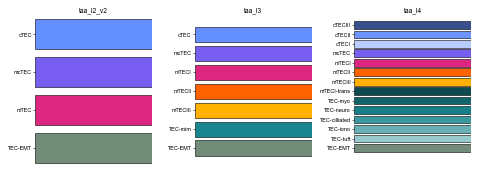

In [17]:
def shade_tint_ramp(base, n, dark=0.45, light=0.55):
    """n colours of one hue: base mixed with black (fraction `dark`) -> base -> base mixed with white (`light`)."""
    if n == 1:
        return [to_hex(base)]
    rgb = np.array(to_rgb(base))
    out = []
    for t in np.linspace(-dark, light, n):
        c = rgb * (1 + t) if t < 0 else rgb + (1 - rgb) * t
        out.append(to_hex(np.clip(c, 0, 1)))
    return out

l3_to_l2 = level_map(obs, is_TEC, 'taa_l3', 'taa_l2_v2')
l4_to_l3 = level_map(obs, is_TEC, 'taa_l4', 'taa_l3')
ct2lin = {lvl: level_map(obs, is_TEC, lvl, 'taa_l2_v2') for lvl in levels}   # cell type -> lineage, for the checks

pal_l3 = {ct: TEC_L3_COLORS_03.get(ct, '#cccccc') for ct in ct_levels['taa_l3']}
pal_l2 = {}
for l3 in ct_levels['taa_l3']:
    pal_l2.setdefault(l3_to_l2[l3], pal_l3[l3])
pal_l2 = {ct: pal_l2.get(ct, '#cccccc') for ct in ct_levels['taa_l2_v2']}
pal_l4 = {}
for parent in ct_levels['taa_l3']:
    kids = [c for c in ct_levels['taa_l4'] if l4_to_l3.get(c) == parent]
    pal_l4.update(dict(zip(kids, shade_tint_ramp(pal_l3[parent], len(kids)))))
pal_l4 = {ct: pal_l4.get(ct, '#cccccc') for ct in ct_levels['taa_l4']}
palettes = {'taa_l2_v2': pal_l2, 'taa_l3': pal_l3, 'taa_l4': pal_l4}
for lvl in levels:
    missing = [ct for ct, c in palettes[lvl].items() if c == '#cccccc']
    if missing:
        print(f'{lvl}: no colour for {missing}')

pal_table = pd.DataFrame([(lvl, ct, (l4_to_l3.get(ct) if lvl == 'taa_l4' else ''), c)
                          for lvl in levels for ct, c in palettes[lvl].items()],
                         columns=['level', 'cell_type', 'taa_l3_parent', 'color'])
pal_table.to_csv(f'{results_path}/{PREFIX}_palette_{today}.csv', index=False)
pal_table.loc[pal_table['level'] == 'taa_l4']

fig, axes = plt.subplots(1, len(levels), figsize=(2.0 * len(levels), 2.2))
for ax, lvl in zip(axes, levels):
    cts = ct_levels[lvl]
    ypos = list(range(len(cts)))[::-1]
    ax.barh(ypos, [1] * len(cts), color=[palettes[lvl][c] for c in cts])
    ax.set_yticks(ypos)
    ax.set_yticklabels(cts)
    ax.set_xticks([])
    ax.set_title(lvl, fontsize=6)
    sns.despine(ax=ax, left=True, bottom=True)
plt.tight_layout()
plt.savefig(f'{plot_path}/{PREFIX}_palette_swatches_{today}.pdf', bbox_inches='tight')
plt.show()

top panel: TEC fraction of all cells from 64 TOT samples


,mean_prop,sd_prop,n_donors
age_group,,,
infant,0.001841,0.004911,19
paed,0.001176,0.000870,6
adult,0.017365,0.034132,13


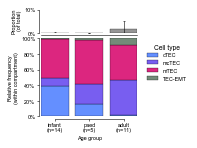

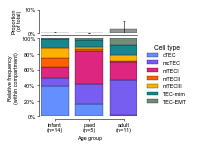

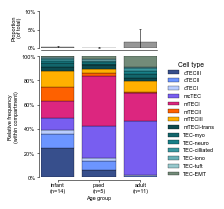

donors per age group (all sorts, >= MIN_CELLS TEC cells): {'infant': 14, 'paed': 5, 'adult': 11}


In [18]:
top = compartment_fraction_by_age(T_sample, sorts=TOT_SORTS)
print(f'top panel: TEC fraction of all cells from {int(T_sample["sort"].isin(TOT_SORTS).sum())} TOT samples')
top

PER_DONOR_MAIN, REL, N_DONORS = {}, {}, {}
for lvl in levels:
    PER_DONOR_MAIN[lvl] = donor_composition(COUNTS[lvl], T_sample, sorts=MAIN_SORTS, min_cells=MIN_CELLS,
                                            denominator='TEC')
    REL[lvl], N_DONORS[lvl] = composition_by_age(PER_DONOR_MAIN[lvl], ct_levels[lvl])
    n_ct = len(ct_levels[lvl])
    fig = stacked_bar_plot(REL[lvl], top=top, palette=palettes[lvl], n_donors=N_DONORS[lvl],
                           figsize=calc_figsize(width=48 if lvl == 'taa_l4' else 40, height=70 if n_ct > 8 else 45),
                           legend_kwargs={'ncol': 2 if n_ct > 16 else 1},
                           plt_path=f'{plot_path}/{PREFIX}_{lvl}_relFreq_stackedbar_allSorts_{today}.pdf')
    plt.show()
    out = REL[lvl].copy()
    out.columns = [str(c) for c in out.columns]
    out.to_csv(f'{results_path}/{PREFIX}_{lvl}_stackedbar_allSorts_{today}.csv')
print('donors per age group (all sorts, >= MIN_CELLS TEC cells):', N_DONORS['taa_l4'].to_dict())

<BarContainer object of 3 artists>

<BarContainer object of 3 artists>

<BarContainer object of 3 artists>

<BarContainer object of 3 artists>

<BarContainer object of 3 artists>

...

<BarContainer object of 3 artists>

[Text(0, 0, 'infant (n=14)'),
 Text(1, 0, 'paed (n=5)'),
 Text(2, 0, 'adult (n=11)')]

(0.0, 1.0)

Text(0.5, 1.0, 'within TEC-mim')

Text(0, 0.5, 'Relative frequency\n(within TEC-mim)')

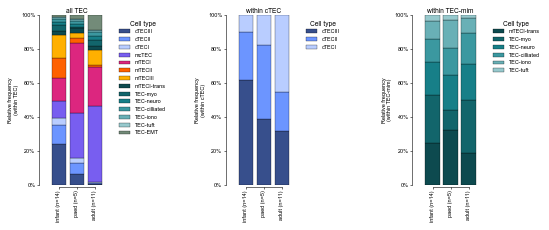

infant   paed  adult
panel          cell_type                          
all TEC        cTECIII         0.242  0.062  0.006
               cTECII          0.113  0.069  0.004
               cTECI           0.038  0.028  0.009
               mcTEC           0.101  0.262  0.446
               mTECI           0.135  0.415  0.230
               mTECII          0.118  0.026  0.012
               mTECIII         0.135  0.033  0.086
               mTECI-trans     0.027  0.027  0.023
               TEC-myo         0.031  0.010  0.038
               TEC-neuro       0.021  0.017  0.026
               TEC-cilliated   0.015  0.013  0.022
               TEC-iono        0.012  0.014  0.011
               TEC-tuft        0.004  0.002  0.002
               TEC-EMT         0.009  0.020  0.086
within cTEC    cTECIII         0.616  0.391  0.319
               cTECII          0.287  0.432  0.230
               cTECI           0.097  0.177  0.451
within TEC-mim mTECI-trans     0.246  0.326  0.190
               TEC-myo         0.284  0.118  0.313
               TEC-neuro       0.194  0.203  0.210
               TEC-cilliated   0.134  0.158  0.180
               TEC-iono        0.106  0.167  0.087
               TEC-tuft        0.036  0.028  0.019

In [19]:
# taa_l4 in focus: the full stack, and the parents with several subsets renormalised within the parent
# (mean over donors of the within-TEC proportions, renormalised over the parent's subsets)
parents = [p for p in ct_levels['taa_l3'] if sum(l4_to_l3.get(c) == p for c in ct_levels['taa_l4']) > 1]
panels = {'all TEC': ct_levels['taa_l4']}
panels.update({f'within {p}': [c for c in ct_levels['taa_l4'] if l4_to_l3.get(c) == p] for p in parents})

fig, axes = plt.subplots(1, len(panels), figsize=calc_figsize(width=183, height=70), gridspec_kw={'wspace': 1.6})
zoom_tables = {}
for ax, (name, cts) in zip(np.atleast_1d(axes), panels.items()):
    rel, n = composition_by_age(PER_DONOR_MAIN['taa_l4'], cts)
    zoom_tables[name] = rel
    bottom = np.zeros(len(age_order))
    for ct in cts:
        vals = rel.loc[ct].values
        ax.bar(range(len(age_order)), vals, bottom=bottom, label=ct, color=palettes['taa_l4'][ct],
               linewidth=0.25, width=0.8)
        bottom += vals
    ax.set_xticks(range(len(age_order)))
    ax.set_xticklabels([f'{a} (n={int(n[a])})' for a in age_order])
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    ax.set_title(name, fontsize=6)
    ax.set_ylabel('Relative frequency\n(within TEC)' if name == 'all TEC' else f'Relative frequency\n({name})')
    ax.legend(title='Cell type', frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
    sns.despine(ax=ax, offset=2, trim=True)
    ax.tick_params(axis='x', labelrotation=90)   # after despine: trim=True resets the rotation
plt.savefig(f'{plot_path}/{PREFIX}_taa_l4_relFreq_stackedbar_allSorts_zoom_{today}.pdf', bbox_inches='tight')
plt.show()
zoom = pd.concat(zoom_tables, names=['panel', 'cell_type'])
zoom.columns = [str(c) for c in zoom.columns]
zoom.to_csv(f'{results_path}/{PREFIX}_taa_l4_stackedbar_allSorts_zoom_{today}.csv')
zoom.round(3)

In [20]:
# The plotted numbers (columns sum to 1 over the cell types of a level)
for lvl in levels:
    t = REL[lvl].copy()
    t.columns = [f'{a} (n={int(N_DONORS[lvl][a])})' for a in t.columns]
    print(lvl)
    display(t.round(3))

taa_l2_v2


,infant (n=14),paed (n=5),adult (n=11)
cell_type,,,
cTEC,0.392,0.160,0.019
mcTEC,0.101,0.262,0.446
mTEC,0.498,0.558,0.449
TEC-EMT,0.009,0.020,0.086


taa_l3


,infant (n=14),paed (n=5),adult (n=11)
cell_type,,,
cTEC,0.392,0.160,0.019
mcTEC,0.101,0.262,0.446
mTECI,0.135,0.415,0.230
mTECII,0.118,0.026,0.012
mTECIII,0.135,0.033,0.086
TEC-mim,0.110,0.084,0.121
TEC-EMT,0.009,0.020,0.086


taa_l4


,infant (n=14),paed (n=5),adult (n=11)
cell_type,,,
cTECIII,0.242,0.062,0.006
cTECII,0.113,0.069,0.004
cTECI,0.038,0.028,0.009
mcTEC,0.101,0.262,0.446
mTECI,0.135,0.415,0.230
mTECII,0.118,0.026,0.012
mTECIII,0.135,0.033,0.086
mTECI-trans,0.027,0.027,0.023
TEC-myo,0.031,0.010,0.038


### Consistency checks

Per-sample subset counts must add up to `n_TEC`; summing the finer levels within each `taa_l2_v2` lineage must
reproduce the `taa_l2_v2` fractions; every stack sums to 1.

In [21]:
for lvl in levels:
    assert (COUNTS[lvl].sum(axis=1) == T_sample['n_TEC']).all(), f'{lvl}: per-sample counts != n_TEC'
print('per-sample counts sum to n_TEC at every level')
l2 = REL['taa_l2_v2']
for lvl in ['taa_l3', 'taa_l4']:
    by_lin = REL[lvl].groupby(REL[lvl].index.map(ct2lin[lvl])).sum().reindex(l2.index)
    print(f'max |{lvl} summed within lineage - taa_l2_v2| = {float((by_lin - l2).abs().max().max()):.2e}')
print('stacks sum to:', REL['taa_l4'].sum(axis=0).round(6).to_dict())

per-sample counts sum to n_TEC at every level
max |taa_l3 summed within lineage - taa_l2_v2| = 1.11e-16
max |taa_l4 summed within lineage - taa_l2_v2| = 5.55e-17
stacks sum to: {'infant': 1.0, 'paed': 1.0, 'adult': 1.0}


## 5. Frequency change with age - all sorts pooled

Per-donor frequencies **within TEC** from the same donors as the stacked bars (all sorts, >= MIN_CELLS TEC cells).
`plot_grouped_boxplot` runs a **Kruskal-Wallis test per cell type across age groups** and, where p < 0.05, a
**post-hoc Dunn test** (FDR-BH within a cell type) whose significant pairs are annotated; it writes
`_summaryStats.csv`, `_kruskal.csv` and `_dunn.csv`. KW p-values are raw across cell types, as in 03. Pink boxes =
one magenta tint per age group.

In [22]:
freq = PER_DONOR_MAIN
for lvl in levels:
    freq[lvl].to_csv(f'{results_path}/{PREFIX}_perDonor_propWithinTEC_{lvl}_allSorts_{today}.csv', index=False)
keep = samples_passing(T_sample, MAIN_SORTS, MIN_CELLS)
print(f'{T_sample.loc[keep, "n_TEC"].sum():,} TEC cells / {len(keep)} samples / {T_sample.loc[keep, "donor"].nunique()} donors')
T_sample.loc[keep].groupby(['age_group', 'sort'], observed=True).agg(n_samples=('donor', 'size'),
                                                                    n_donors=('donor', 'nunique')).unstack('age_group').fillna(0).astype(int)

88,586 TEC cells / 49 samples / 30 donors


n_samples            n_donors           
age_group       infant paed adult   infant paed adult
sort                                                 
CD205+CD49F+         1    0     0        1    0     0
CD45N                9    3     8        8    2     7
CD45NCD3N            0    0     2        0    0     2
EPCAM                6    5     5        5    5     5
EPCAM+CD205+         1    0     2        1    0     2
TOT                  2    0     5        1    0     4

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

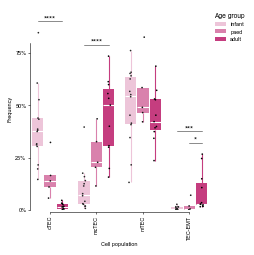

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

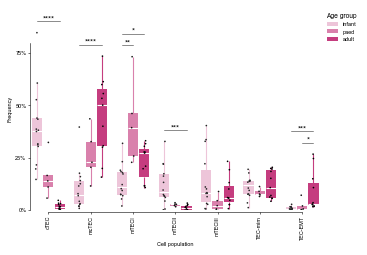

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

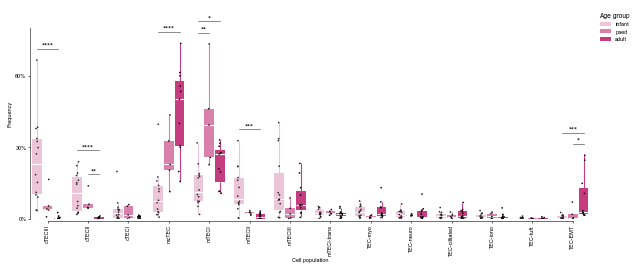

In [23]:
pink = get_tint_palette(THY_COLORS['magenta'], n=len(age_order), min_tint=0.3)
figsizes = {'taa_l2_v2': (3.2, 3.2), 'taa_l3': (4.6, 3.2), 'taa_l4': (8.0, 3.4)}
legend_kwargs = {'bbox_to_anchor': (1.01, 1), 'loc': 'upper left', 'frameon': False}   # outside the axes

for lvl in levels:
    for suffix in ['_kruskal.csv', '_dunn.csv', '_summaryStats.csv']:   # no stale stats from an earlier run
        f = f'{results_path}/{PREFIX}_{lvl}_freq{suffix}'
        if os.path.exists(f):
            os.remove(f)
    df = freq[lvl].rename(columns={'cell_type': lvl})
    df['age_group'] = pd.Categorical(df['age_group'], categories=age_order, ordered=True)
    order = [c for c in ct_levels[lvl] if c in set(df[lvl])]
    plot_grouped_boxplot(data=df, x=lvl, y='prop', hue='age_group', order=order, hue_order=age_order,
                         x_label='Cell population', y_label='Frequency',   # within TEC
                         legend_title='Age group', add_stats=True, format_percent=True,
                         figsize=figsizes[lvl], remove_legend=False, palette=pink, legend_kwargs=legend_kwargs,
                         save_stats=f'{results_path}/{PREFIX}_{lvl}_freq')
    plt.gca().yaxis.set_major_locator(plt.MaxNLocator(4))   # short axes - the default ticks overlap
    plt.savefig(f'{plot_path}/{PREFIX}_{lvl}_freq_boxplot_pink_{today}.pdf', bbox_inches='tight')
    plt.show()

In [24]:
# Compact summary: median frequency per age group + Kruskal-Wallis per cell type (+ adult/infant ratio).
# NB Dunn p-values are FDR-BH adjusted within a cell type; the KW p-values are raw across cell types.
summary_freq = []
for lvl in levels:
    kw = pd.read_csv(f'{results_path}/{PREFIX}_{lvl}_freq_kruskal.csv', index_col=0)
    med = (freq[lvl].pivot_table(index='cell_type', columns='age_group', values='prop', aggfunc='median')
           .reindex(index=ct_levels[lvl], columns=age_order))
    kw.index = kw.index.astype(str)
    t = med.join(kw[['statistic', 'pvalue', 'pvalue_signif']])
    t.insert(0, 'level', lvl)
    t['adult_vs_infant'] = t['adult'] / t['infant']
    summary_freq.append(t)
summary_freq = pd.concat(summary_freq).rename_axis('cell_type').reset_index()
summary_freq.to_csv(f'{results_path}/{PREFIX}_freq_KWsummary_{today}.csv', index=False)
summary_freq.round(4)

dunn = [pd.read_csv(f'{results_path}/{PREFIX}_{lvl}_freq_dunn.csv', index_col=0).rename(columns={lvl: 'cell_type'}).assign(level=lvl)
        for lvl in levels if os.path.exists(f'{results_path}/{PREFIX}_{lvl}_freq_dunn.csv')]
if dunn:
    dunn = pd.concat(dunn)
    dunn.loc[dunn['pvalue'] < 0.05].sort_values(['level', 'pvalue'])[['level', 'cell_type', 'group1', 'group2', 'pvalue', 'pvalue_signif']]
else:
    print('no Dunn results - no cell type had a significant Kruskal-Wallis test')

,cell_type,level,infant,paed,adult,statistic,pvalue,pvalue_signif,adult_vs_infant
0,cTEC,taa_l2_v2,0.3786,0.1398,0.0167,22.9716,0.0000,****,0.0442
1,mcTEC,taa_l2_v2,0.0740,0.2287,0.5015,17.8299,0.0001,***,6.7728
2,mTEC,taa_l2_v2,0.5466,0.4907,0.4226,2.1349,0.3439,NaN,0.7731
3,TEC-EMT,taa_l2_v2,0.0057,0.0059,0.0284,15.5422,0.0004,***,4.9762
4,cTEC,taa_l3,0.3786,0.1398,0.0167,22.9716,0.0000,****,0.0442
5,mcTEC,taa_l3,0.0740,0.2287,0.5015,17.8299,0.0001,***,6.7728
6,mTECI,taa_l3,0.1125,0.3939,0.2726,12.7386,0.0017,**,2.4226
7,mTECII,taa_l3,0.0854,0.0279,0.0099,15.3934,0.0005,***,0.1158
8,mTECIII,taa_l3,0.0823,0.0217,0.0593,4.9602,0.0837,NaN,0.7200
9,TEC-mim,taa_l3,0.1197,0.0771,0.1078,0.8536,0.6526,NaN,0.9009


,level,cell_type,group1,group2,pvalue,pvalue_signif
5,taa_l2_v2,cTEC,adult,infant,0.000005,****
8,taa_l2_v2,mcTEC,adult,infant,0.000093,****
2,taa_l2_v2,TEC-EMT,adult,infant,0.000326,***
11,taa_l2_v2,TEC-EMT,adult,paed,0.032058,*
5,taa_l3,cTEC,adult,infant,0.000005,****
14,taa_l3,mcTEC,adult,infant,0.000093,****
11,taa_l3,mTECII,adult,infant,0.000281,***
2,taa_l3,TEC-EMT,adult,infant,0.000326,***
7,taa_l3,mTECI,paed,infant,0.002884,**
8,taa_l3,mTECI,adult,infant,0.024712,*


## 6. Composition under each sort, and what each sort does within a donor

Per-donor **within-TEC** proportions (every donor weighs the same) under each bracket.

1. **Composition under each sort** - the stacked bars redrawn from every single sort and the composites (all sorts
   pooled, TOT + CD45N, TEC-enriched). Donor numbers are written above the bars.
2. **Within-donor paired sorts** - donors sorted two ways; per cell type `log2 [sort A / sort B]` per donor
   (half-cell pseudo-count), holding donor and age fixed. Uses `MIN_CELLS_PAIRED` TEC cells per sample; the
   Wilcoxon signed-rank test is reported from 5 donors and cannot go below p = 0.0625 at n = 5 (0.031 at n = 6).

Section 7 then asks how these composition differences change the age statistics.

In [25]:
comp_summary, comp_donor = {}, {}
for lvl in levels:
    comp_summary[lvl], comp_donor[lvl] = composition_by_bracket(COUNTS[lvl], T_sample, BRACKETS, min_cells=MIN_CELLS)
    comp_summary[lvl].to_csv(f'{results_path}/{PREFIX}_{lvl}_composition_bySort_{today}.csv', index=False)
    comp_donor[lvl].to_csv(f'{results_path}/{PREFIX}_perDonor_propWithinTEC_{lvl}_bySort_{today}.csv', index=False)

# donors per bracket x age group (identical at every level)
(comp_donor['taa_l2_v2'].groupby(['bracket', 'age_group'], observed=True)['donor'].nunique()
 .unstack('age_group').reindex(columns=age_order).fillna(0).astype(int))

# taa_l2_v2 composition per bracket x age group (rows sum to 1)
wide = (comp_summary['taa_l2_v2'].pivot_table(index=['bracket', 'age_group'], columns='cell_type', values='mean_prop', observed=True)
        .reindex(columns=ct_levels['taa_l2_v2']))
wide.round(3)

age_group,infant,paed,adult
bracket,,,
TOT,1,0,4
CD45N,8,2,7
CD45NCD3N,0,0,2
EPCAM,5,5,5
EPCAM+CD205+,1,0,2
CD205+CD49F+,1,0,0
all sorts,14,5,11
TOT+CD45N,9,2,8
TEC-enriched,7,5,7


cell_type                        cTEC  mcTEC   mTEC  TEC-EMT
bracket              age_group                              
TOT                  adult      0.017  0.495  0.391    0.096
                     infant     0.367  0.111  0.522    0.000
CD45N                adult      0.018  0.413  0.409    0.161
                     infant     0.295  0.172  0.520    0.013
                     paed       0.087  0.294  0.548    0.071
CD45NCD3N            adult      0.007  0.526  0.443    0.024
EPCAM                adult      0.022  0.438  0.483    0.057
                     infant     0.408  0.057  0.532    0.003
                     paed       0.184  0.259  0.553    0.003
EPCAM+CD205+         adult      0.009  0.422  0.554    0.015
                     infant     0.526  0.143  0.330    0.002
CD205+CD49F+         infant     0.847  0.019  0.133    0.001
all sorts            adult      0.019  0.446  0.449    0.086
                     infant     0.392  0.101  0.498    0.009
                     paed       0.160  0.262  0.558    0.020
TOT+CD45N            adult      0.021  0.428  0.421    0.130
                     infant     0.303  0.165  0.520    0.012
                     paed       0.087  0.294  0.548    0.071
TEC-enriched         adult      0.018  0.433  0.503    0.045
                     infant     0.487  0.064  0.446    0.003
                     paed       0.184  0.259  0.553    0.003
all w/o EPCAM        adult      0.017  0.437  0.439    0.107
                     infant     0.372  0.125  0.492    0.011
                     paed       0.087  0.294  0.548    0.071
all w/o CD45N        adult      0.019  0.442  0.480    0.058
                     infant     0.502  0.062  0.433    0.003
                     paed       0.184  0.259  0.553    0.003
all w/o TOT          adult      0.017  0.443  0.450    0.091
                     infant     0.385  0.102  0.505    0.009
                     paed       0.160  0.262  0.558    0.020
all w/o EPCAM+CD205+ adult      0.020  0.439  0.447    0.093
                     infant     0.382  0.119  0.490    0.009
                     paed       0.160  0.262  0.558    0.020
all w/o CD205+CD49F+ adult      0.019  0.446  0.449    0.086
                     infant     0.357  0.107  0.526    0.009
                     paed       0.160  0.262  0.558    0.020
all w/o CD45NCD3N    adult      0.020  0.446  0.441    0.093
                     infant     0.392  0.101  0.498    0.009
                     paed       0.160  0.262  0.558    0.020

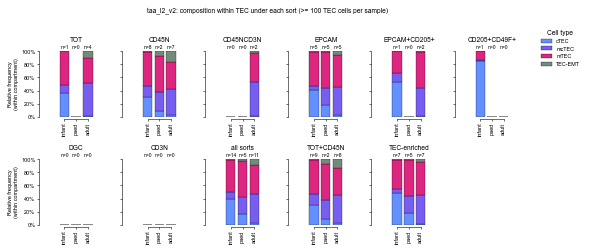

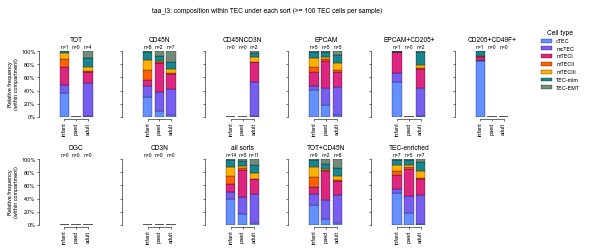

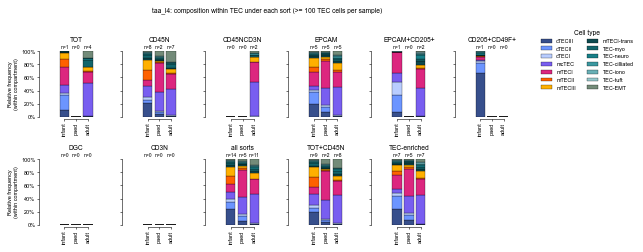

In [26]:
grid_brackets = list(SORT_BRACKETS) + list(COMPOSITE_BRACKETS)
for lvl in levels:
    n_ct = len(ct_levels[lvl])
    fig = composition_grid_plot(comp_summary[lvl], ct_levels[lvl], palettes[lvl], brackets=grid_brackets,
                                ncols=6, panel_size=(0.95, 1.5), legend_kwargs={'ncol': 2 if n_ct > 9 else 1},
                                plt_path=f'{plot_path}/{PREFIX}_{lvl}_composition_bySort_grid_{today}.pdf',
                                title=f'{lvl}: composition within TEC under each sort (>= {MIN_CELLS} TEC cells per sample)')
    plt.show()

### Within-donor paired sorts

Each pair lists the donors that have a passing sample in both sorts, then the per-cell-type summary (mean
proportion under each sort, median log2 ratio, donors up / down, Wilcoxon p where n >= 5). Plots (taa_l3 and
taa_l4): left, one point per donor and cell type, black tick = median, dashed = no effect; right, proportion
under sort B (x) vs sort A (y), identity line dashed, values < 0.1 % drawn at the floor.


==== EPCAM_vs_CD45N: 6 donors with both sorts ====


,donor,age_group,n_cells_a,n_cells_b
0,A45,adult,1527,268
1,A51,adult,1995,670
2,A53,adult,703,599
3,A56,adult,3974,5559
4,Z12,paed,735,246
5,Z17,paed,2061,11402


EPCAM_vs_CD45N / taa_l2_v2:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,6,0.080,0.039,1.292,6,0,0.031,taa_l2_v2,EPCAM_vs_CD45N
mcTEC,6,0.422,0.302,0.304,5,1,0.219,taa_l2_v2,EPCAM_vs_CD45N
mTEC,6,0.490,0.464,-0.056,2,4,1.000,taa_l2_v2,EPCAM_vs_CD45N
TEC-EMT,6,0.008,0.195,-3.868,0,6,0.031,taa_l2_v2,EPCAM_vs_CD45N


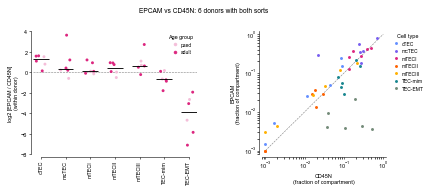

EPCAM_vs_CD45N / taa_l3:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,6,0.080,0.039,1.292,6,0,0.031,taa_l3,EPCAM_vs_CD45N
mcTEC,6,0.422,0.302,0.304,5,1,0.219,taa_l3,EPCAM_vs_CD45N
mTECI,6,0.315,0.262,0.087,4,2,0.562,taa_l3,EPCAM_vs_CD45N
mTECII,6,0.018,0.014,0.400,5,1,0.156,taa_l3,EPCAM_vs_CD45N
mTECIII,6,0.063,0.057,0.641,5,1,0.062,taa_l3,EPCAM_vs_CD45N
TEC-mim,6,0.094,0.131,-0.705,2,4,0.156,taa_l3,EPCAM_vs_CD45N
TEC-EMT,6,0.008,0.195,-3.868,0,6,0.031,taa_l3,EPCAM_vs_CD45N


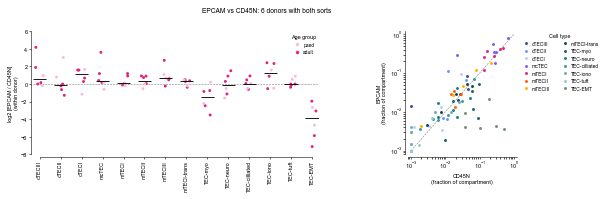

EPCAM_vs_CD45N / taa_l4:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTECIII,6,0.028,0.019,0.565,4,1,0.188,taa_l4,EPCAM_vs_CD45N
cTECII,6,0.032,0.012,-0.104,2,3,1.000,taa_l4,EPCAM_vs_CD45N
cTECI,6,0.020,0.008,1.133,5,1,0.156,taa_l4,EPCAM_vs_CD45N
mcTEC,6,0.422,0.302,0.304,5,1,0.219,taa_l4,EPCAM_vs_CD45N
mTECI,6,0.315,0.262,0.087,4,2,0.562,taa_l4,EPCAM_vs_CD45N
mTECII,6,0.018,0.014,0.400,5,1,0.156,taa_l4,EPCAM_vs_CD45N
mTECIII,6,0.063,0.057,0.641,5,1,0.062,taa_l4,EPCAM_vs_CD45N
mTECI-trans,6,0.027,0.026,0.332,4,2,0.219,taa_l4,EPCAM_vs_CD45N
TEC-myo,6,0.021,0.056,-1.525,1,5,0.062,taa_l4,EPCAM_vs_CD45N



==== TOT_vs_CD45N: 5 donors with both sorts ====


,donor,age_group,n_cells_a,n_cells_b
0,A43,adult,69,4856
1,A51,adult,172,670
2,A56,adult,233,5559
3,A67,adult,137,204
4,A70,adult,69,69


TOT_vs_CD45N / taa_l2_v2:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,5,0.016,0.010,0.404,3,1,0.625,taa_l2_v2,TOT_vs_CD45N
mcTEC,5,0.534,0.451,0.153,4,1,0.438,taa_l2_v2,TOT_vs_CD45N
mTEC,5,0.371,0.362,-0.137,1,4,0.625,taa_l2_v2,TOT_vs_CD45N
TEC-EMT,5,0.080,0.176,-0.759,1,4,0.188,taa_l2_v2,TOT_vs_CD45N


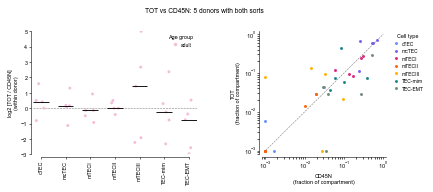

TOT_vs_CD45N / taa_l3:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,5,0.016,0.010,0.404,3,1,0.625,taa_l3,TOT_vs_CD45N
mcTEC,5,0.534,0.451,0.153,4,1,0.438,taa_l3,TOT_vs_CD45N
mTECI,5,0.164,0.187,-0.144,1,4,0.438,taa_l3,TOT_vs_CD45N
mTECII,5,0.009,0.006,0.000,2,1,0.750,taa_l3,TOT_vs_CD45N
mTECIII,5,0.065,0.034,1.424,3,2,0.625,taa_l3,TOT_vs_CD45N
TEC-mim,5,0.134,0.135,-0.251,2,3,1.000,taa_l3,TOT_vs_CD45N
TEC-EMT,5,0.080,0.176,-0.759,1,4,0.188,taa_l3,TOT_vs_CD45N


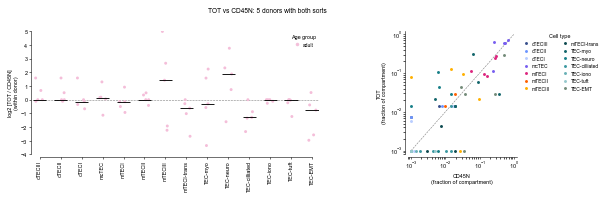

TOT_vs_CD45N / taa_l4:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTECIII,5,0.004,0.001,0.000,2,1,0.500,taa_l4,TOT_vs_CD45N
cTECII,5,0.004,0.002,0.000,2,1,0.500,taa_l4,TOT_vs_CD45N
cTECI,5,0.007,0.008,-0.138,1,3,0.875,taa_l4,TOT_vs_CD45N
mcTEC,5,0.534,0.451,0.153,4,1,0.438,taa_l4,TOT_vs_CD45N
mTECI,5,0.164,0.187,-0.144,1,4,0.438,taa_l4,TOT_vs_CD45N
mTECII,5,0.009,0.006,0.000,2,1,0.750,taa_l4,TOT_vs_CD45N
mTECIII,5,0.065,0.034,1.424,3,2,0.625,taa_l4,TOT_vs_CD45N
mTECI-trans,5,0.004,0.010,-0.618,0,4,0.125,taa_l4,TOT_vs_CD45N
TEC-myo,5,0.088,0.108,-0.302,2,3,1.000,taa_l4,TOT_vs_CD45N



==== EPCAM+CD205+_vs_CD45N: 3 donors with both sorts ====


,donor,age_group,n_cells_a,n_cells_b
0,A67,adult,819,204
1,A70,adult,1296,69
2,U40,infant,2622,3505


EPCAM+CD205+_vs_CD45N / taa_l2_v2:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,3,0.182,0.086,0.804,2,1,NaN,taa_l2_v2,EPCAM+CD205+_vs_CD45N
mcTEC,3,0.329,0.477,-1.082,1,2,NaN,taa_l2_v2,EPCAM+CD205+_vs_CD45N
mTEC,3,0.479,0.333,0.761,2,1,NaN,taa_l2_v2,EPCAM+CD205+_vs_CD45N
TEC-EMT,3,0.010,0.105,-2.396,0,3,NaN,taa_l2_v2,EPCAM+CD205+_vs_CD45N


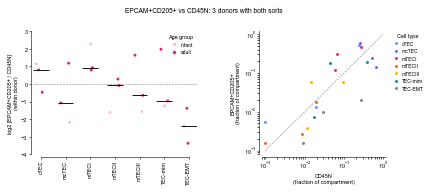

EPCAM+CD205+_vs_CD45N / taa_l3:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,3,0.182,0.086,0.804,2,1,NaN,taa_l3,EPCAM+CD205+_vs_CD45N
mcTEC,3,0.329,0.477,-1.082,1,2,NaN,taa_l3,EPCAM+CD205+_vs_CD45N
mTECI,3,0.303,0.133,0.924,3,0,NaN,taa_l3,EPCAM+CD205+_vs_CD45N
mTECII,3,0.008,0.009,-0.087,1,2,NaN,taa_l3,EPCAM+CD205+_vs_CD45N
mTECIII,3,0.041,0.040,-0.647,1,2,NaN,taa_l3,EPCAM+CD205+_vs_CD45N
TEC-mim,3,0.128,0.151,-0.966,1,2,NaN,taa_l3,EPCAM+CD205+_vs_CD45N
TEC-EMT,3,0.010,0.105,-2.396,0,3,NaN,taa_l3,EPCAM+CD205+_vs_CD45N


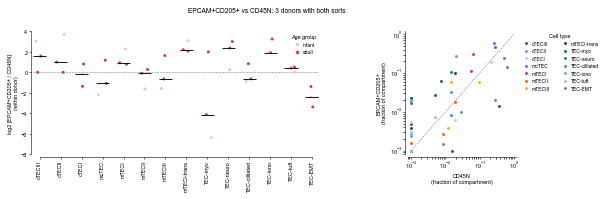

EPCAM+CD205+_vs_CD45N / taa_l4:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTECIII,3,0.023,0.003,1.581,2,0,NaN,taa_l4,EPCAM+CD205+_vs_CD45N
cTECII,3,0.091,0.007,0.997,2,0,NaN,taa_l4,EPCAM+CD205+_vs_CD45N
cTECI,3,0.067,0.076,-0.137,1,2,NaN,taa_l4,EPCAM+CD205+_vs_CD45N
mcTEC,3,0.329,0.477,-1.082,1,2,NaN,taa_l4,EPCAM+CD205+_vs_CD45N
mTECI,3,0.303,0.133,0.924,3,0,NaN,taa_l4,EPCAM+CD205+_vs_CD45N
mTECII,3,0.008,0.009,-0.087,1,2,NaN,taa_l4,EPCAM+CD205+_vs_CD45N
mTECIII,3,0.041,0.040,-0.647,1,2,NaN,taa_l4,EPCAM+CD205+_vs_CD45N
mTECI-trans,3,0.042,0.007,2.200,3,0,NaN,taa_l4,EPCAM+CD205+_vs_CD45N
TEC-myo,3,0.014,0.128,-4.128,1,2,NaN,taa_l4,EPCAM+CD205+_vs_CD45N



==== CD45NCD3N_vs_CD45N: 1 donors with both sorts ====


,donor,age_group,n_cells_a,n_cells_b
0,A67,adult,427,204


CD45NCD3N_vs_CD45N / taa_l2_v2:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,1,0.005,0.020,-1.628,0,1,NaN,taa_l2_v2,CD45NCD3N_vs_CD45N
mcTEC,1,0.651,0.520,0.324,1,0,NaN,taa_l2_v2,CD45NCD3N_vs_CD45N
mTEC,1,0.314,0.431,-0.456,0,1,NaN,taa_l2_v2,CD45NCD3N_vs_CD45N
TEC-EMT,1,0.030,0.029,0.046,1,0,NaN,taa_l2_v2,CD45NCD3N_vs_CD45N


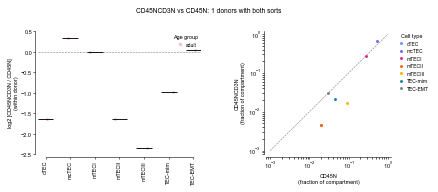

CD45NCD3N_vs_CD45N / taa_l3:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,1,0.005,0.020,-1.628,0,1,NaN,taa_l3,CD45NCD3N_vs_CD45N
mcTEC,1,0.651,0.520,0.324,1,0,NaN,taa_l3,CD45NCD3N_vs_CD45N
mTECI,1,0.272,0.275,-0.015,0,1,NaN,taa_l3,CD45NCD3N_vs_CD45N
mTECII,1,0.005,0.020,-1.628,0,1,NaN,taa_l3,CD45NCD3N_vs_CD45N
mTECIII,1,0.016,0.093,-2.343,0,1,NaN,taa_l3,CD45NCD3N_vs_CD45N
TEC-mim,1,0.021,0.044,-0.985,0,1,NaN,taa_l3,CD45NCD3N_vs_CD45N
TEC-EMT,1,0.030,0.029,0.046,1,0,NaN,taa_l3,CD45NCD3N_vs_CD45N


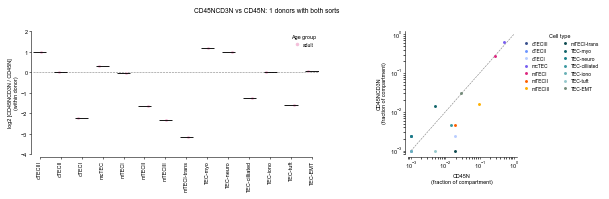

CD45NCD3N_vs_CD45N / taa_l4:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTECIII,1,0.002,0.000,0.968,1,0,NaN,taa_l4,CD45NCD3N_vs_CD45N
cTECII,1,0.000,0.000,0.000,0,0,NaN,taa_l4,CD45NCD3N_vs_CD45N
cTECI,1,0.002,0.020,-2.202,0,1,NaN,taa_l4,CD45NCD3N_vs_CD45N
mcTEC,1,0.651,0.520,0.324,1,0,NaN,taa_l4,CD45NCD3N_vs_CD45N
mTECI,1,0.272,0.275,-0.015,0,1,NaN,taa_l4,CD45NCD3N_vs_CD45N
mTECII,1,0.005,0.020,-1.628,0,1,NaN,taa_l4,CD45NCD3N_vs_CD45N
mTECIII,1,0.016,0.093,-2.343,0,1,NaN,taa_l4,CD45NCD3N_vs_CD45N
mTECI-trans,1,0.000,0.020,-3.170,0,1,NaN,taa_l4,CD45NCD3N_vs_CD45N
TEC-myo,1,0.014,0.005,1.166,1,0,NaN,taa_l4,CD45NCD3N_vs_CD45N



==== EPCAM_vs_TOT: 3 donors with both sorts ====


,donor,age_group,n_cells_a,n_cells_b
0,A51,adult,1995,172
1,A56,adult,3974,233
2,T07,infant,2247,282


EPCAM_vs_TOT / taa_l2_v2:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,3,0.074,0.124,-0.762,1,2,NaN,taa_l2_v2,EPCAM_vs_TOT
mcTEC,3,0.493,0.314,0.179,3,0,NaN,taa_l2_v2,EPCAM_vs_TOT
mTEC,3,0.427,0.453,-0.295,1,2,NaN,taa_l2_v2,EPCAM_vs_TOT
TEC-EMT,3,0.005,0.108,-1.363,1,2,NaN,taa_l2_v2,EPCAM_vs_TOT


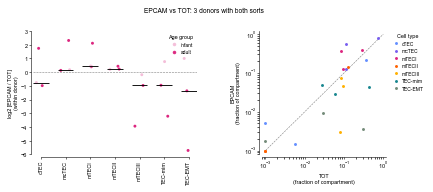

EPCAM_vs_TOT / taa_l3:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTEC,3,0.074,0.124,-0.762,1,2,NaN,taa_l3,EPCAM_vs_TOT
mcTEC,3,0.493,0.314,0.179,3,0,NaN,taa_l3,EPCAM_vs_TOT
mTECI,3,0.297,0.154,0.448,3,0,NaN,taa_l3,EPCAM_vs_TOT
mTECII,3,0.049,0.042,0.230,3,0,NaN,taa_l3,EPCAM_vs_TOT
mTECIII,3,0.041,0.085,-0.969,0,3,NaN,taa_l3,EPCAM_vs_TOT
TEC-mim,3,0.041,0.172,-0.956,1,2,NaN,taa_l3,EPCAM_vs_TOT
TEC-EMT,3,0.005,0.108,-1.363,1,2,NaN,taa_l3,EPCAM_vs_TOT


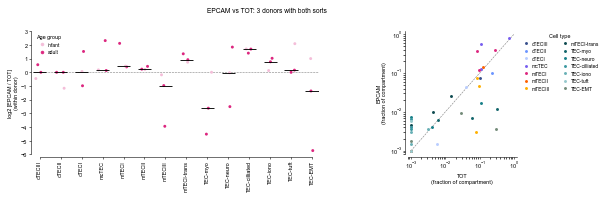

EPCAM_vs_TOT / taa_l4:


,n_donors,mean_prop_a,mean_prop_b,median_log2_ratio,n_up,n_down,wilcoxon_p,level,pair
cell_type,,,,,,,,,
cTECIII,3,0.025,0.034,0.000,1,1,NaN,taa_l4,EPCAM_vs_TOT
cTECII,3,0.033,0.075,0.000,0,1,NaN,taa_l4,EPCAM_vs_TOT
cTECI,3,0.016,0.016,0.059,2,1,NaN,taa_l4,EPCAM_vs_TOT
mcTEC,3,0.493,0.314,0.179,3,0,NaN,taa_l4,EPCAM_vs_TOT
mTECI,3,0.297,0.154,0.448,3,0,NaN,taa_l4,EPCAM_vs_TOT
mTECII,3,0.049,0.042,0.230,3,0,NaN,taa_l4,EPCAM_vs_TOT
mTECIII,3,0.041,0.085,-0.969,0,3,NaN,taa_l4,EPCAM_vs_TOT
mTECI-trans,3,0.013,0.006,0.924,3,0,NaN,taa_l4,EPCAM_vs_TOT
TEC-myo,3,0.008,0.127,-2.621,1,2,NaN,taa_l4,EPCAM_vs_TOT


In [27]:
paired_summary = []
for sort_a, sort_b in PAIRS:
    tag = pair_tag(sort_a, sort_b)
    for lvl in levels:
        pt = paired_sort_table(COUNTS[lvl], T_sample, sort_a, sort_b, min_cells=MIN_CELLS_PAIRED)
        if pt.empty:
            print(f'{tag} / {lvl}: no donor has both sorts passing {MIN_CELLS_PAIRED} TEC cells')
            continue
        pt.to_csv(f'{results_path}/{PREFIX}_{lvl}_pairedSorts_{tag}_{today}.csv', index=False)
        s = paired_sort_summary(pt, ctypes=ct_levels[lvl]).assign(level=lvl, pair=tag)
        paired_summary.append(s.reset_index())
        if lvl == 'taa_l2_v2':
            print(f'\n==== {tag}: {pt["donor"].nunique()} donors with both sorts ====')
            display(pt.drop_duplicates('donor')[['donor', 'age_group', 'n_cells_a', 'n_cells_b']]
                    .sort_values(['age_group', 'donor']).reset_index(drop=True))
        if lvl in ['taa_l3', 'taa_l4']:
            fig = paired_sort_plot(pt, ct_levels[lvl], palette=palettes[lvl],
                                   plt_path=f'{plot_path}/{PREFIX}_{lvl}_pairedSorts_{tag}_{today}.pdf')
            plt.show()
        print(f'{tag} / {lvl}:')
        display(s.round(3))
paired_summary = pd.concat(paired_summary, ignore_index=True)
paired_summary.to_csv(f'{results_path}/{PREFIX}_pairedSorts_summary_{today}.csv', index=False)

<Axes: xlabel='pair', ylabel='cell_type'>

Text(0.5, 14.964444444444446, '')

Text(54.94444444444444, 0.5, '')

Text(0.5, 1.0, 'taa_l3: within-donor sort effect (A vs B)')

[None, None, None, None, None, None, None, None, None, None]

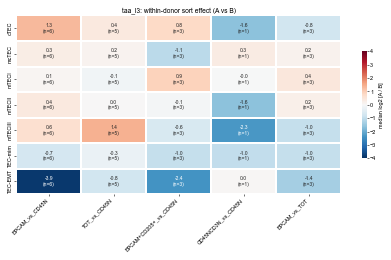

<Axes: xlabel='pair', ylabel='cell_type'>

Text(0.5, 33.444444444444436, '')

Text(54.94444444444444, 0.5, '')

Text(0.5, 1.0, 'taa_l4: within-donor sort effect (A vs B)')

[None, None, None, None, None, None, None, None, None, None]

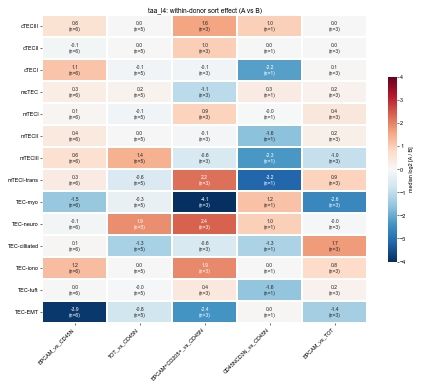

In [28]:
# Overview: median within-donor log2 ratio per cell type (rows) and sort pair (columns), n donors in brackets
for lvl in ['taa_l3', 'taa_l4']:
    ps = paired_summary.loc[paired_summary['level'] == lvl]
    cols = [pair_tag(a, b) for a, b in PAIRS if pair_tag(a, b) in set(ps['pair'])]
    mat = (ps.pivot_table(index='cell_type', columns='pair', values='median_log2_ratio')
           .reindex(index=ct_levels[lvl], columns=cols))
    nd = ps.pivot_table(index='cell_type', columns='pair', values='n_donors').reindex(index=mat.index, columns=mat.columns)
    annot = (mat.round(1).astype(str) + '\n(n=' + nd.fillna(0).astype(int).astype(str) + ')').where(mat.notna(), '')
    fig, ax = plt.subplots(figsize=(0.95 * mat.shape[1] + 1.8, 0.3 * mat.shape[0] + 0.8))
    sns.heatmap(mat, cmap='RdBu_r', center=0, vmin=-4, vmax=4, annot=annot, fmt='', annot_kws={'fontsize': 4.5},
                cbar_kws={'label': 'median log2 [A / B]', 'shrink': 0.6}, linewidths=0.3, linecolor='white', ax=ax)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_title(f'{lvl}: within-donor sort effect (A vs B)', fontsize=6)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
    plt.savefig(f'{plot_path}/{PREFIX}_{lvl}_pairedSorts_heatmap_{today}.pdf', bbox_inches='tight')
    plt.show()

## 7. Significance across sorts

For every bracket (single sorts, composites, *all sorts minus one sort*) and cell type: Kruskal-Wallis across the
age groups with >= `MIN_DONORS_GROUP` donors, Dunn (FDR-BH within the cell type) between those groups, medians
per age group and the direction of change. Brackets with fewer than two such age groups are not testable.

Each result is compared with the pooled reference (`all sorts`, the section-5 boxplots):

| verdict | meaning |
|---|---|
| significant in both / ns in both | the sort bracket agrees with the pooled result |
| **lost, too few donors** (`u`) | pooled significant, bracket not, and donor-matched subsamples of the pooled data reach p < 0.05 in < `POWER_LEVEL` of draws - the loss is expected from the donor numbers alone |
| **lost, despite power** (`L`) | pooled significant, bracket not, although >= `POWER_LEVEL` of donor-matched subsamples are significant - the donors of this bracket show a weaker effect than random donors of the pool, i.e. the sort matters |
| **gained** (`G`) | significant in the bracket only |
| **direction differs** (`D`) | significant in both, opposite direction |

For a leave-one-out bracket, `L` means the result depends on the sort that was left out. *Expected significance*
is computed from `N_SUBSAMPLE` subsamples of the pooled donors with the bracket's donor numbers per age group; it
uses the pooled effect, so it answers "would this many donors have detected the pooled effect?". p-values are raw
(uncorrected across cell types and brackets), as in 03.

In [29]:
SIG = {lvl: significance_by_bracket(comp_donor[lvl]) for lvl in levels}

n_cols = [f'n_{a}' for a in age_order]
bracket_n = (SIG['taa_l4'].groupby('bracket')[n_cols + ['groups_tested', 'testable']].first()
             .reindex([b for b in BRACKETS if b in set(SIG['taa_l4']['bracket'])]))
bracket_n.insert(0, 'group', bracket_n.index.map(BRACKET_GROUP))
bracket_n
print('not testable (fewer than two age groups with >= MIN_DONORS_GROUP donors):',
      bracket_n.index[~bracket_n['testable'].astype(bool)].tolist())
print('no donor passing at all:', [b for b in BRACKETS if b not in bracket_n.index])

# The reference bracket reproduces the Kruskal-Wallis p-values of the section-5 boxplots
for lvl in levels:
    kw_box = pd.read_csv(f'{results_path}/{PREFIX}_{lvl}_freq_kruskal.csv', index_col=0)['pvalue']
    kw_box.index = kw_box.index.astype(str)
    kw_ref = SIG[lvl].loc[SIG[lvl]['bracket'] == REF_BRACKET].set_index('cell_type')['kw_p']
    print(f'{lvl}: max |KW p (boxplot) - KW p ({REF_BRACKET})| = {float((kw_box.reindex(kw_ref.index) - kw_ref).abs().max()):.2e}')

,group,n_infant,n_paed,n_adult,groups_tested,testable
bracket,,,,,,
TOT,single sort,1,0,4,adult,False
CD45N,single sort,8,2,7,"infant,paed,adult",True
CD45NCD3N,single sort,0,0,2,adult,False
EPCAM,single sort,5,5,5,"infant,paed,adult",True
EPCAM+CD205+,single sort,1,0,2,adult,False
CD205+CD49F+,single sort,1,0,0,,False
all sorts,composite,14,5,11,"infant,paed,adult",True
TOT+CD45N,composite,9,2,8,"infant,paed,adult",True
TEC-enriched,composite,7,5,7,"infant,paed,adult",True


not testable (fewer than two age groups with >= MIN_DONORS_GROUP donors): ['TOT', 'CD45NCD3N', 'EPCAM+CD205+', 'CD205+CD49F+']
no donor passing at all: ['DGC', 'CD3N']
taa_l2_v2: max |KW p (boxplot) - KW p (all sorts)| = 5.55e-17
taa_l3: max |KW p (boxplot) - KW p (all sorts)| = 4.66e-15
taa_l4: max |KW p (boxplot) - KW p (all sorts)| = 5.11e-15


In [30]:
%%time
for lvl in levels:
    ref_pd = comp_donor[lvl].loc[comp_donor[lvl]['bracket'].astype(str) == REF_BRACKET]
    es = []
    for br, sub in SIG[lvl].loc[SIG[lvl]['testable']].groupby('bracket', sort=False):
        target = {a: int(sub.iloc[0][f'n_{a}']) for a in sub.iloc[0]['groups_tested'].split(',')}
        e = expected_significance(ref_pd, target, ct_levels[lvl])
        es.append(pd.DataFrame({'bracket': br, 'cell_type': e.index, 'expected_signif': e.values}))
    SIG[lvl] = SIG[lvl].drop(columns=['expected_signif'], errors='ignore').merge(pd.concat(es), on=['bracket', 'cell_type'], how='left')
    SIG[lvl] = classify_vs_reference(SIG[lvl])
    SIG[lvl].to_csv(f'{results_path}/{PREFIX}_{lvl}_significance_bySort_{today}.csv', index=False)

# Checks: (1) the vectorised Kruskal-Wallis equals scipy's on the pooled data; (2) drawing all pooled donors
# (the reference bracket itself) is deterministic, so its expected significance is 1 exactly where p < ALPHA
for lvl in levels:
    ref = SIG[lvl].loc[SIG[lvl]['bracket'] == REF_BRACKET].set_index('cell_type').reindex(ct_levels[lvl])
    ref_pd = comp_donor[lvl].loc[comp_donor[lvl]['bracket'].astype(str) == REF_BRACKET]
    wide = ref_pd.pivot_table(index=['donor', 'age_group'], columns='cell_type', values='prop').reindex(columns=ct_levels[lvl]).fillna(0)
    ages = np.asarray(wide.index.get_level_values('age_group'))
    tested = ref['groups_tested'].iloc[0].split(',')
    p_vec = kruskal_columns([wide.to_numpy()[ages == a] for a in tested])
    ok = ref['kw_p'].to_numpy() < 1
    print(f'{lvl}: max |vectorised KW - scipy KW| = {np.nanmax(np.abs(p_vec[ok] - ref["kw_p"].to_numpy()[ok])):.2e}; '
          f'reference expected significance == (p < ALPHA): {bool(((ref["expected_signif"] == 1) == (ref["kw_p"] < ALPHA)).all())}')

taa_l2_v2: max |vectorised KW - scipy KW| = 0.00e+00; reference expected significance == (p < ALPHA): True
taa_l3: max |vectorised KW - scipy KW| = 0.00e+00; reference expected significance == (p < ALPHA): True
taa_l4: max |vectorised KW - scipy KW| = 0.00e+00; reference expected significance == (p < ALPHA): True
CPU times: user 12.3 s, sys: 11.2 ms, total: 12.3 s
Wall time: 12.3 s


In [31]:
# Verdict counts per bracket, and every pooled result that depends on the sort
show = ['cell_type', 'bracket', 'n_infant', 'n_paed', 'n_adult', 'median_infant', 'median_paed', 'median_adult',
        'kw_p', 'kw_signif', 'ref_kw_p', 'expected_signif', 'verdict']
show = [c for c in show if c in SIG['taa_l4'].columns]
for lvl in levels:
    s = SIG[lvl]
    counts = (s.loc[s['verdict'] != 'reference'].groupby(['bracket', 'verdict']).size().unstack('verdict', fill_value=0)
              .reindex([b for b in BRACKETS if b in set(s['bracket']) and b != REF_BRACKET]))
    print(f'\n==== {lvl}: verdicts per bracket (number of cell types) ====')
    display(counts)
    flagged = s.loc[s['verdict'].isin(['lost, despite power', 'gained', 'significant in both, direction differs'])]
    print(f'{lvl}: results that depend on the sort ({len(flagged)} bracket x cell type):')
    display(flagged[show].sort_values(['cell_type', 'bracket']).round(4))

# Wide p-value table at taa_l4: rows = subsets, columns = brackets, text = p (stars, verdict code)
s = SIG['taa_l4'].loc[SIG['taa_l4']['testable']].copy()
s['text'] = s.apply(lambda r: f"{r['kw_p']:.2g} {r['kw_signif']}" + (f" [{VERDICT_CODE[r['verdict']]}]" if VERDICT_CODE.get(r['verdict']) else ''), axis=1)
wide_l4 = s.pivot(index='cell_type', columns='bracket', values='text').reindex(index=ct_levels['taa_l4'], columns=[b for b in BRACKETS if b in set(s['bracket'])])
wide_l4.to_csv(f'{results_path}/{PREFIX}_taa_l4_significance_bySort_wide_{today}.csv')
wide_l4


==== taa_l2_v2: verdicts per bracket (number of cell types) ====


verdict,"lost, despite power","lost, too few donors",not testable,ns in both,significant in both
bracket,,,,,
TOT,0,0,4,0,0
CD45N,1,0,0,1,2
CD45NCD3N,0,0,4,0,0
EPCAM,0,1,0,1,2
EPCAM+CD205+,0,0,4,0,0
CD205+CD49F+,0,0,4,0,0
TOT+CD45N,1,0,0,1,2
TEC-enriched,0,0,0,1,3
all w/o EPCAM,0,0,0,1,3


taa_l2_v2: results that depend on the sort (2 bracket x cell type):


,cell_type,bracket,n_infant,n_paed,n_adult,median_infant,median_paed,median_adult,kw_p,kw_signif,ref_kw_p,expected_signif,verdict
7,mcTEC,CD45N,8,2,7,0.1337,0.2939,0.5196,0.1064,ns,0.0001,1.0,"lost, despite power"
31,mcTEC,TOT+CD45N,9,2,8,0.1263,0.2939,0.5446,0.0602,ns,0.0001,1.0,"lost, despite power"



==== taa_l3: verdicts per bracket (number of cell types) ====


...


==== taa_l4: verdicts per bracket (number of cell types) ====


verdict,gained,"lost, despite power","lost, too few donors",not testable,ns in both,significant in both
bracket,,,,,,
TOT,0,0,0,14,0,0
CD45N,0,1,0,0,8,5
CD45NCD3N,0,0,0,14,0,0
EPCAM,0,0,2,0,8,4
EPCAM+CD205+,0,0,0,14,0,0
CD205+CD49F+,0,0,0,14,0,0
TOT+CD45N,1,1,0,0,7,5
TEC-enriched,1,2,0,0,7,4
all w/o EPCAM,0,0,0,0,8,6


taa_l4: results that depend on the sort (11 bracket x cell type):


,cell_type,bracket,n_infant,n_paed,n_adult,median_infant,median_paed,median_adult,kw_p,kw_signif,ref_kw_p,expected_signif,verdict
143,TEC-myo,all w/o CD45N,7,5,9,0.0129,0.0068,0.0250,0.0176,*,0.1091,0.148,gained
118,cTECI,TEC-enriched,7,5,7,0.0373,0.0178,0.0054,0.0373,*,0.1097,0.038,gained
146,cTECI,all w/o CD45N,7,5,9,0.0373,0.0178,0.0077,0.0249,*,0.1097,0.066,gained
121,mTECI,TEC-enriched,7,5,7,0.1792,0.4110,0.2589,0.1444,ns,0.0017,0.982,"lost, despite power"
149,mTECI,all w/o CD45N,7,5,9,0.1792,0.4110,0.2589,0.0976,ns,0.0017,0.992,"lost, despite power"
123,mTECII,TEC-enriched,7,5,7,0.0667,0.0279,0.0183,0.0980,ns,0.0005,0.898,"lost, despite power"
151,mTECII,all w/o CD45N,7,5,9,0.0667,0.0279,0.0135,0.0572,ns,0.0005,0.974,"lost, despite power"
110,mTECIII,TOT+CD45N,9,2,8,0.0837,0.0091,0.0584,0.0407,*,0.0837,0.064,gained
194,mTECIII,all w/o CD205+CD49F+,13,5,11,0.0836,0.0217,0.0593,0.0478,*,0.0837,0.046,gained
27,mcTEC,CD45N,8,2,7,0.1337,0.2939,0.5196,0.1064,ns,0.0001,1.000,"lost, despite power"


bracket,CD45N,EPCAM,all sorts,TOT+CD45N,TEC-enriched,all w/o EPCAM,all w/o CD45N,all w/o TOT,all w/o EPCAM+CD205+,all w/o CD205+CD49F+,all w/o CD45NCD3N
cell_type,,,,,,,,,,,
cTECIII,0.0026 **,0.0092 **,1.9e-05 ***,0.0016 **,0.0016 **,0.00025 ***,0.00064 ***,2.9e-05 ***,5.6e-05 ***,2.7e-05 ***,3.3e-05 ***
cTECII,0.0026 **,0.003 **,3.7e-05 ***,0.0012 **,0.00049 ***,0.0003 ***,0.00015 ***,6.9e-05 ***,7.4e-05 ***,4.8e-05 ***,6.8e-05 ***
cTECI,0.37 ns,0.18 ns,0.11 ns,0.33 ns,0.037 * [G],0.18 ns,0.025 * [G],0.086 ns,0.15 ns,0.15 ns,0.12 ns
mcTEC,0.11 ns [L],0.0093 **,0.00013 ***,0.06 ns [L],0.002 **,0.006 **,0.00082 ***,0.0002 ***,0.00067 ***,0.00021 ***,0.00022 ***
mTECI,0.0031 **,0.13 ns [u],0.0017 **,0.0076 **,0.14 ns [L],0.0056 **,0.098 ns [L],0.0023 **,0.00099 ***,0.0028 **,0.0022 **
mTECII,0.0089 **,0.0092 **,0.00045 ***,0.0046 **,0.098 ns [L],0.0048 **,0.057 ns [L],0.00053 ***,0.00083 ***,0.00011 ***,0.00089 ***
mTECIII,0.091 ns,0.18 ns,0.084 ns,0.041 * [G],0.35 ns,0.099 ns,0.15 ns,0.12 ns,0.1 ns,0.048 * [G],0.079 ns
mTECI-trans,0.84 ns,0.62 ns,0.72 ns,0.74 ns,0.91 ns,0.98 ns,0.86 ns,0.86 ns,0.41 ns,0.61 ns,0.88 ns
TEC-myo,0.26 ns,0.21 ns,0.11 ns,0.41 ns,0.13 ns,0.49 ns,0.018 * [G],0.075 ns,0.1 ns,0.069 ns,0.11 ns


<Axes: xlabel='bracket', ylabel='cell_type'>

[Text(0.5, 0, 'CD45N (8/2/7)'),
 Text(1.5, 0, 'EPCAM (5/5/5)'),
 Text(2.5, 0, 'all sorts (14/5/11)'),
 Text(3.5, 0, 'TOT+CD45N (9/2/8)'),
 Text(4.5, 0, 'TEC-enriched (7/5/7)'),
 Text(5.5, 0, 'all w/o EPCAM (10/2/10)'),
 Text(6.5, 0, 'all w/o CD45N (7/5/9)'),
 Text(7.5, 0, 'all w/o TOT (14/5/10)'),
 Text(8.5, 0, 'all w/o EPCAM+CD205+ (14/5/10)'),
 Text(9.5, 0, 'all w/o CD205+CD49F+ (13/5/11)'),
 Text(10.5, 0, 'all w/o CD45NCD3N (14/5/10)')]

Text(0.5, 46.116444444444426, 'sort bracket (donors infant/paed/adult)')

Text(71.94444444444444, 0.5, '')

Text(0.5, 1.0, 'taa_l4: age effect per sort bracket vs all sorts pooled\nstars = KW p; u = lost, too few donors; L = lost despite power; G = gained; D = direction differs;\nsecond line = expected significance with these donor numbers (500 subsamples of the pool)')

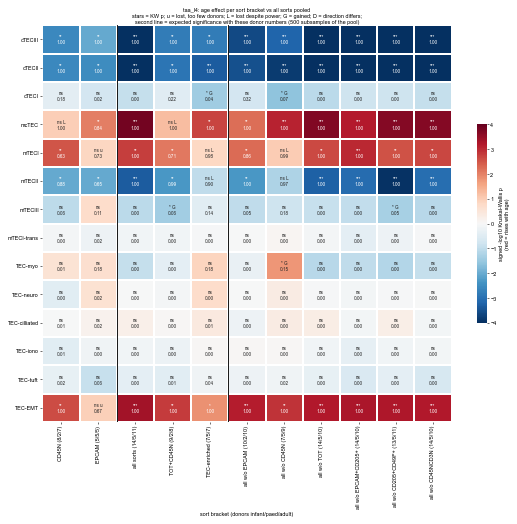

<Axes: xlabel='bracket', ylabel='cell_type'>

[Text(0.5, 0, 'CD45N (8/2/7)'),
 Text(1.5, 0, 'EPCAM (5/5/5)'),
 Text(2.5, 0, 'all sorts (14/5/11)'),
 Text(3.5, 0, 'TOT+CD45N (9/2/8)'),
 Text(4.5, 0, 'TEC-enriched (7/5/7)'),
 Text(5.5, 0, 'all w/o EPCAM (10/2/10)'),
 Text(6.5, 0, 'all w/o CD45N (7/5/9)'),
 Text(7.5, 0, 'all w/o TOT (14/5/10)'),
 Text(8.5, 0, 'all w/o EPCAM+CD205+ (14/5/10)'),
 Text(9.5, 0, 'all w/o CD205+CD49F+ (13/5/11)'),
 Text(10.5, 0, 'all w/o CD45NCD3N (14/5/10)')]

Text(0.5, 23.94044444444444, 'sort bracket (donors infant/paed/adult)')

Text(71.94444444444444, 0.5, '')

Text(0.5, 1.0, 'taa_l3: age effect per sort bracket vs all sorts pooled\nstars = KW p; u = lost, too few donors; L = lost despite power; G = gained; D = direction differs;\nsecond line = expected significance with these donor numbers (500 subsamples of the pool)')

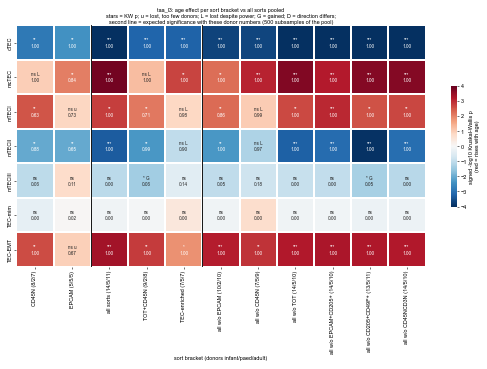

<Axes: xlabel='bracket', ylabel='cell_type'>

[Text(0.5, 0, 'CD45N (8/2/7)'),
 Text(1.5, 0, 'EPCAM (5/5/5)'),
 Text(2.5, 0, 'all sorts (14/5/11)'),
 Text(3.5, 0, 'TOT+CD45N (9/2/8)'),
 Text(4.5, 0, 'TEC-enriched (7/5/7)'),
 Text(5.5, 0, 'all w/o EPCAM (10/2/10)'),
 Text(6.5, 0, 'all w/o CD45N (7/5/9)'),
 Text(7.5, 0, 'all w/o TOT (14/5/10)'),
 Text(8.5, 0, 'all w/o EPCAM+CD205+ (14/5/10)'),
 Text(9.5, 0, 'all w/o CD205+CD49F+ (13/5/11)'),
 Text(10.5, 0, 'all w/o CD45NCD3N (14/5/10)')]

Text(0.5, 14.436444444444444, 'sort bracket (donors infant/paed/adult)')

Text(71.94444444444444, 0.5, '')

Text(0.5, 1.0, 'taa_l2_v2: age effect per sort bracket vs all sorts pooled\nstars = KW p; u = lost, too few donors; L = lost despite power; G = gained; D = direction differs;\nsecond line = expected significance with these donor numbers (500 subsamples of the pool)')

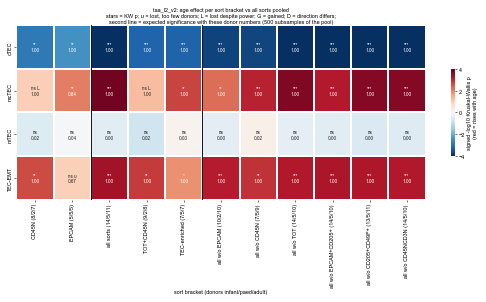

In [32]:
# Heatmap per level: colour = signed -log10 KW p (red = rises with age), text = stars [verdict code] and the
# expected significance at the bracket's donor numbers; black lines separate single sorts | composites | minus one
for lvl in ['taa_l4', 'taa_l3', 'taa_l2_v2']:
    s = SIG[lvl].loc[SIG[lvl]['testable']].copy()
    cols = [b for b in BRACKETS if b in set(s['bracket'])]
    s['signed'] = s['direction'].fillna(0) * -np.log10(s['kw_p'].clip(lower=1e-10))
    s['text'] = s.apply(lambda r: r['kw_signif'] + (f" {VERDICT_CODE[r['verdict']]}" if VERDICT_CODE.get(r['verdict']) else '')
                        + f"\n{r['expected_signif']:.2f}", axis=1)
    mat = s.pivot(index='cell_type', columns='bracket', values='signed').reindex(index=ct_levels[lvl], columns=cols)
    annot = s.pivot(index='cell_type', columns='bracket', values='text').reindex(index=ct_levels[lvl], columns=cols).fillna('')
    ncount = s.groupby('bracket')[[f'n_{a}' for a in age_order]].first()
    xlabels = [f"{b} ({'/'.join(str(int(ncount.loc[b, f'n_{a}'])) for a in age_order)})" for b in cols]
    fig, ax = plt.subplots(figsize=(0.55 * len(cols) + 2.2, 0.36 * len(mat) + 1.4))
    sns.heatmap(mat, cmap='RdBu_r', center=0, vmin=-4, vmax=4, annot=annot, fmt='', annot_kws={'fontsize': 4.2},
                cbar_kws={'label': 'signed -log10 Kruskal-Wallis p\n(red = rises with age)', 'shrink': 0.5},
                linewidths=0.3, linecolor='white', ax=ax)
    ax.set_xticklabels(xlabels, rotation=90)
    ax.set_xlabel(f'sort bracket (donors {"/".join(age_order)})')
    ax.set_ylabel('')
    groups = [BRACKET_GROUP[b] for b in cols]
    for i in range(1, len(cols)):
        if groups[i] != groups[i - 1]:
            ax.axvline(i, color='k', linewidth=0.8)
    ax.set_title(f'{lvl}: age effect per sort bracket vs all sorts pooled\n'
                 f'stars = KW p; u = lost, too few donors; L = lost despite power; G = gained; D = direction differs;\n'
                 f'second line = expected significance with these donor numbers ({N_SUBSAMPLE} subsamples of the pool)',
                 fontsize=5)
    plt.savefig(f'{plot_path}/{PREFIX}_{lvl}_significance_bySort_heatmap_{today}.pdf', bbox_inches='tight')
    plt.show()

### Boxplots per sort bracket (taa_l3, taa_l4)

The section-5 boxplots redrawn from each testable single sort and composite (not the leave-one-out brackets), with
the age groups that have >= `MIN_DONORS_GROUP` donors, so the stars match the table above. Stats are saved with a
`_sort<bracket>` suffix.

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

Text(0.5, 1.0, 'CD45N: infant n=8, paed n=2, adult n=7')

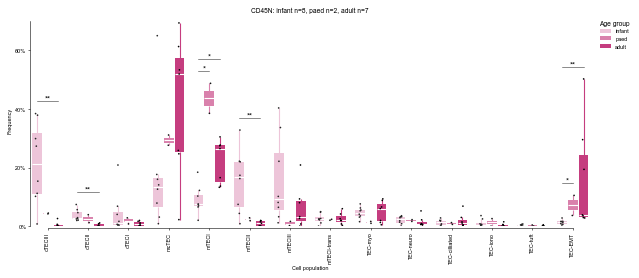

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))


/tmp/ipykernel_3825457/1440501839.py:77: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  g = sns.stripplot(data=data, x=x, y=y, order=order, dodge=True, jitter=True, hue=hue,


<Axes: xlabel='Cell population', ylabel='Frequency'>

Text(0.5, 1.0, 'EPCAM: infant n=5, paed n=5, adult n=5')

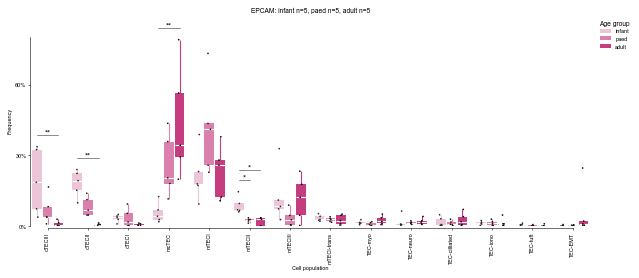

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

Text(0.5, 1.0, 'TOT+CD45N: infant n=9, paed n=2, adult n=8')

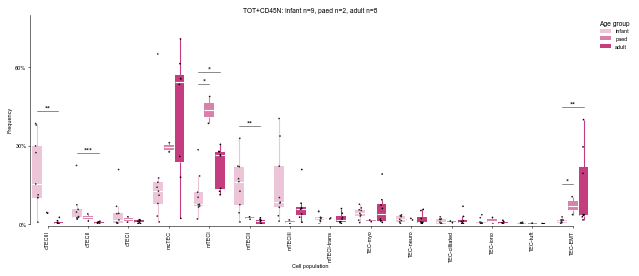

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

Text(0.5, 1.0, 'TEC-enriched: infant n=7, paed n=5, adult n=7')

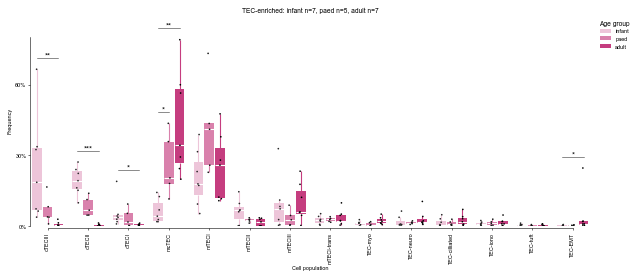

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

Text(0.5, 1.0, 'CD45N: infant n=8, paed n=2, adult n=7')

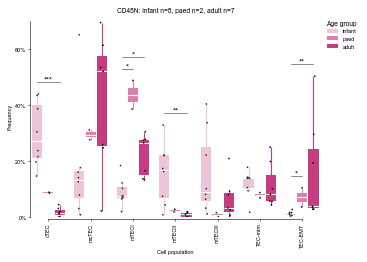

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

Text(0.5, 1.0, 'EPCAM: infant n=5, paed n=5, adult n=5')

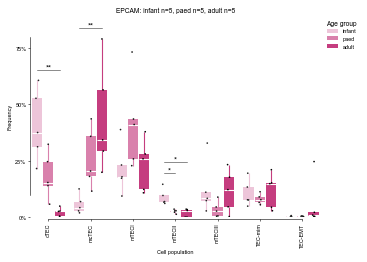

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

Text(0.5, 1.0, 'TOT+CD45N: infant n=9, paed n=2, adult n=8')

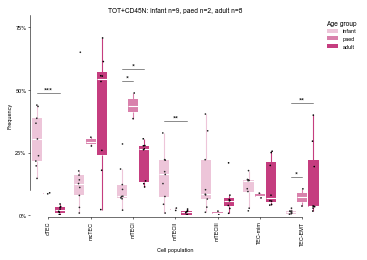

Performing Kruskal-Wallis and Dunn tests


/tmp/ipykernel_3825457/1440501839.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  out = data.groupby(grouping_var, observed=True).apply(_kw)
/tmp/ipykernel_3825457/1440501839.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  res = data.groupby(grouping_var, observed=True).apply(lambda k: sp.posthoc_dunn(k, val_col=y, group_col=x, p_adjust='fdr_bh'))
/tmp/ipykernel_3825457/1440501839.py:77: FutureWar

<Axes: xlabel='Cell population', ylabel='Frequency'>

Text(0.5, 1.0, 'TEC-enriched: infant n=7, paed n=5, adult n=7')

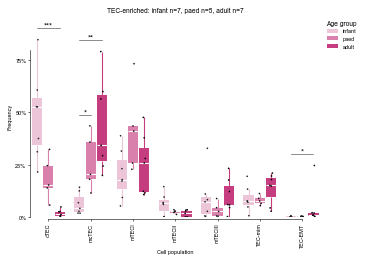

In [33]:
safe = lambda b: b.replace('+', 'p').replace(' ', '').replace('/', '').replace('(', '').replace(')', '')
box_brackets = [b for b in list(SORT_BRACKETS) + list(COMPOSITE_BRACKETS) if b != REF_BRACKET]
for lvl in ['taa_l4', 'taa_l3']:
    testable_b = set(SIG[lvl].loc[SIG[lvl]['testable'], 'bracket'])
    for b in [x for x in box_brackets if x in testable_b]:
        pdn = comp_donor[lvl].loc[comp_donor[lvl]['bracket'].astype(str) == b]
        n_age = pdn.groupby('age_group')['donor'].nunique()
        ages = [a for a in age_order if n_age.get(a, 0) >= MIN_DONORS_GROUP]
        df = pdn.loc[pdn['age_group'].isin(ages)].rename(columns={'cell_type': lvl}).copy()
        df['age_group'] = pd.Categorical(df['age_group'], categories=ages, ordered=True)
        stem = f'{results_path}/{PREFIX}_{lvl}_freq_sort{safe(b)}'
        for suffix in ['_kruskal.csv', '_dunn.csv', '_summaryStats.csv']:
            if os.path.exists(stem + suffix):
                os.remove(stem + suffix)
        plot_grouped_boxplot(data=df, x=lvl, y='prop', hue='age_group', hue_order=ages,
                             order=[c for c in ct_levels[lvl] if c in set(df[lvl])],
                             x_label='Cell population', y_label='Frequency', legend_title='Age group',
                             add_stats=True, format_percent=True, figsize=figsizes[lvl], remove_legend=False,
                             palette=[pink[age_order.index(a)] for a in ages], legend_kwargs=legend_kwargs,
                             save_stats=stem)
        plt.gca().yaxis.set_major_locator(plt.MaxNLocator(4))
        plt.title(f'{b}: ' + ', '.join(f'{a} n={int(n_age[a])}' for a in ages), fontsize=6)
        plt.savefig(f'{plot_path}/{PREFIX}_{lvl}_freq_boxplot_pink_sort{safe(b)}_{today}.pdf', bbox_inches='tight')
        plt.show()

## Notes (2026-09-15 run, v6 object + curatedAnno_v12)

**Pooled quantification (all sorts, >= 100 TEC cells per sample):** 49 samples / 30 donors (infant 14, paed 5,
adult 11); samples per sort: CD45N 20, EPCAM 16, TOT 7, EPCAM+CD205+ 3, CD45NCD3N 2, CD205+CD49F+ 1. At `taa_l3`
the bars match the stacked bar of 03 by eye (infant cTEC 39 %, paed mTECI 42 %, adult mcTEC 45 %, adult TEC-EMT
9 %), although 03 used an older object and annotation and also showed `aged`.

**`taa_l4` composition, infant -> paed -> adult:** cTECIII 24 -> 6 -> 0.6 %, cTECII 11 -> 7 -> 0.4 %, cTECI
4 -> 3 -> 0.9 %; mcTEC 10 -> 26 -> 45 %; mTECI 14 -> 42 -> 23 %; mTECII 12 -> 3 -> 1 %; mTECIII 14 -> 3 -> 9 %;
the six mimetic subsets 11 -> 8 -> 12 % together and each flat; TEC-EMT 1 -> 2 -> 9 %. Within cTEC the balance
moves from cTECIII (62 % of cTEC in infants) to cTECI (45 % in adults).

**Pooled Kruskal-Wallis at `taa_l4`:** cTECIII p = 2e-5, cTECII 4e-5, mcTEC 1.3e-4, TEC-EMT 4e-4, mTECII 5e-4,
mTECI 2e-3; cTECI, mTECIII and every mimetic subset n.s.

**Significance across sorts** (11 testable brackets; TOT, CD45NCD3N, EPCAM+CD205+ and CD205+CD49F+ on their own
have fewer than two age groups with >= 2 donors; DGC and CD3N have no passing sample):
- **Robust to the sort:** cTECIII and cTECII loss are significant in all 11 brackets. The TEC-EMT rise is
  significant everywhere except EPCAM alone, where it is lost with expected significance 0.67 (just under the
  0.8 cut-off); the paired analysis shows EPCAM sorting depletes TEC-EMT ~15-fold. The mcTEC rise survives
  leaving out any single sort (without EPCAM p = 0.006).
- **Depends on the CD45N samples:** the mTECI rise and mTECII loss are lost in TEC-enriched and in all-without-CD45N,
  although donor-matched subsamples of the pool reach p < 0.05 in 90-99 % of draws. In EPCAM alone mTECI is lost
  (expected 0.73) while mTECII stays significant.
- **Weaker without EPCAM infants:** the mcTEC rise is n.s. in CD45N (p = 0.11) and TOT+CD45N (p = 0.06) despite
  expected significance 1.0. EPCAM-sorted infants carry very little mcTEC (median 4 % vs 13 % in CD45N infants),
  which sharpens the pooled trend.
- **Gains are marginal:** cTECI (TEC-enriched, all-without-CD45N), TEC-myo (all-without-CD45N) and mTECIII
  (TOT+CD45N, all-without-CD205+CD49F+) reach p = 0.018-0.048 with expected significance <= 0.15, uncorrected -
  not robust.